In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\DELL\Downloads\dataset pfe.csv")
df.rename(columns={'Car': 'Car_Park'}, inplace=True)

In [3]:
df

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car_Park,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,68 Studley St,2,h,NaN,SS,Jellis,3/09/2016,2.5,3067.0,...,1.0,1.0,126.0,NaN,NaN,Yarra City Council,-37.80140,144.99580,Northern Metropolitan,4019.0
1,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra City Council,-37.79960,144.99840,Northern Metropolitan,4019.0
2,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra City Council,-37.80790,144.99340,Northern Metropolitan,4019.0
3,Abbotsford,18/659 Victoria St,3,u,NaN,VB,Rounds,4/02/2016,2.5,3067.0,...,2.0,1.0,0.0,NaN,NaN,Yarra City Council,-37.81140,145.01160,Northern Metropolitan,4019.0
4,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra City Council,-37.80930,144.99440,Northern Metropolitan,4019.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34852,Yarraville,13 Burns St,4,h,1480000.0,PI,Jas,24/02/2018,6.3,3013.0,...,1.0,3.0,593.0,NaN,NaN,Maribyrnong City Council,-37.81053,144.88467,Western Metropolitan,6543.0
34853,Yarraville,29A Murray St,2,h,888000.0,SP,Sweeney,24/02/2018,6.3,3013.0,...,2.0,1.0,98.0,104.0,2018.0,Maribyrnong City Council,-37.81551,144.88826,Western Metropolitan,6543.0
34854,Yarraville,147A Severn St,2,t,705000.0,S,Jas,24/02/2018,6.3,3013.0,...,1.0,2.0,220.0,120.0,2000.0,Maribyrnong City Council,-37.82286,144.87856,Western Metropolitan,6543.0
34855,Yarraville,12/37 Stephen St,3,h,1140000.0,SP,hockingstuart,24/02/2018,6.3,3013.0,...,NaN,NaN,NaN,NaN,NaN,Maribyrnong City Council,NaN,NaN,Western Metropolitan,6543.0


In [7]:
# ✅ Identifier le nombre de doublons avant suppression
print("Nombre de doublons avant suppression :", df.duplicated().sum())

# ✅ Supprimer les doublons directement dans df
df.drop_duplicates(inplace=True)

# ✅ Vérifier après suppression
print("Nombre de doublons après suppression :", df.duplicated().sum())

# ✅ Afficher la taille avant et après
print("\nTaille du dataset après suppression :", df.shape)


Nombre de doublons avant suppression : 1
Nombre de doublons après suppression : 0

Taille du dataset après suppression : (34856, 21)


In [9]:
print(df.isnull().sum())

Suburb               0
Address              0
Rooms                0
Type                 0
Price             7609
Method               0
SellerG              0
Date                 0
Distance             1
Postcode             1
Bedroom2          8217
Bathroom          8226
Car_Park          8728
Landsize         11810
BuildingArea     21115
YearBuilt        19306
CouncilArea          3
Lattitude         7976
Longtitude        7976
Regionname           3
Propertycount        3
dtype: int64


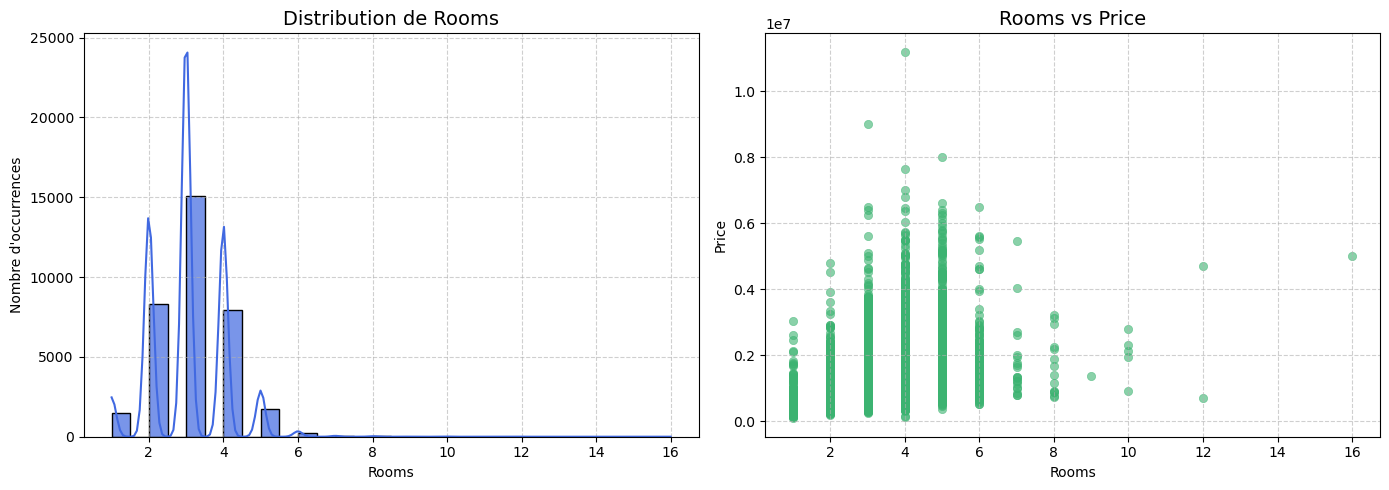

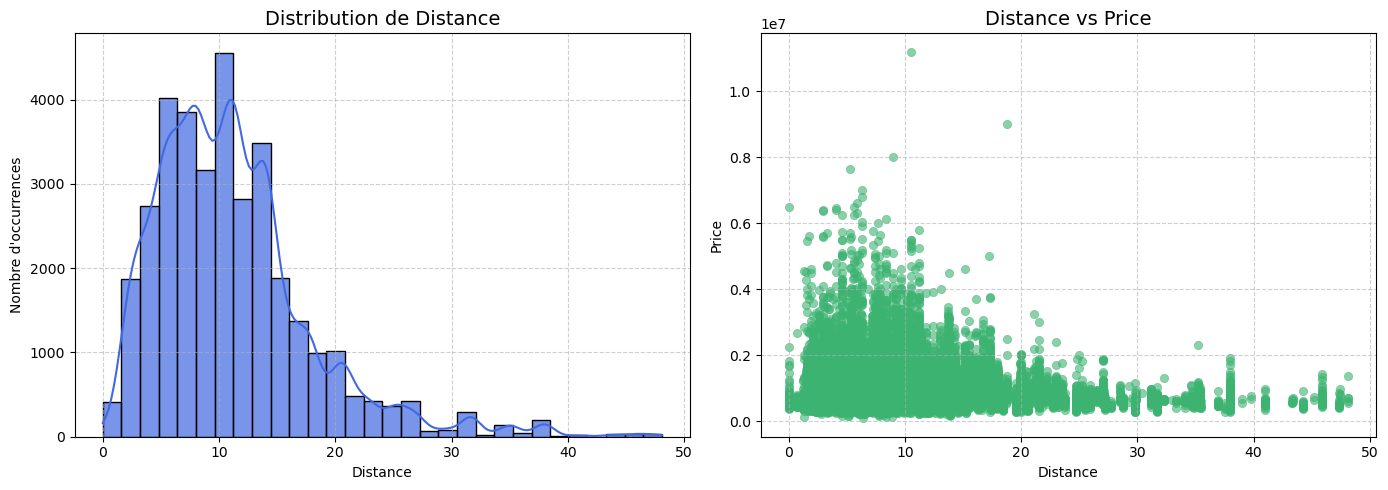

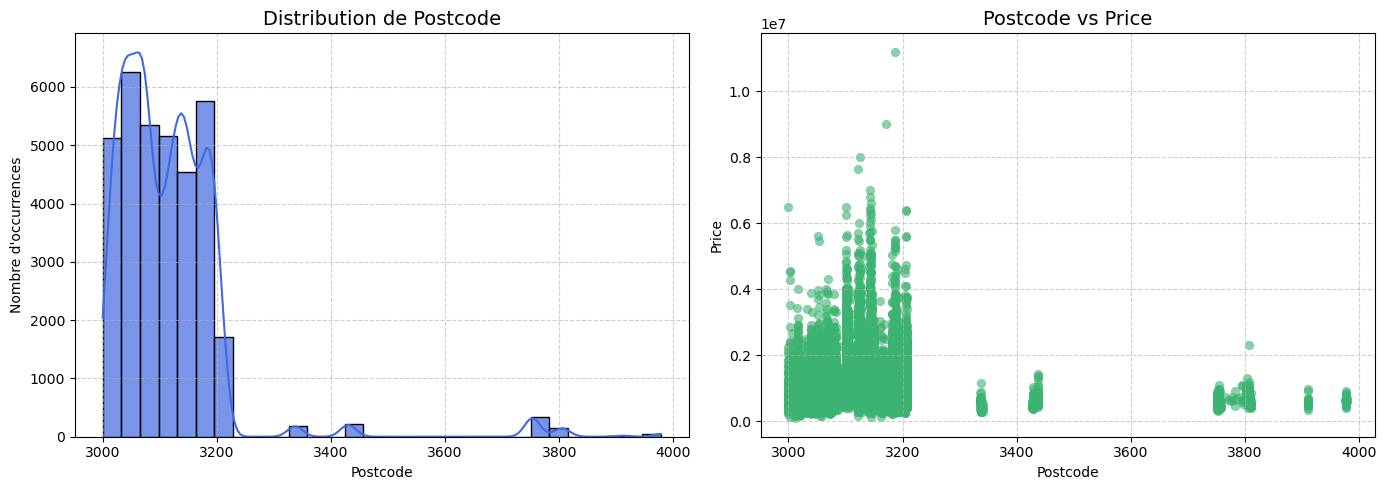

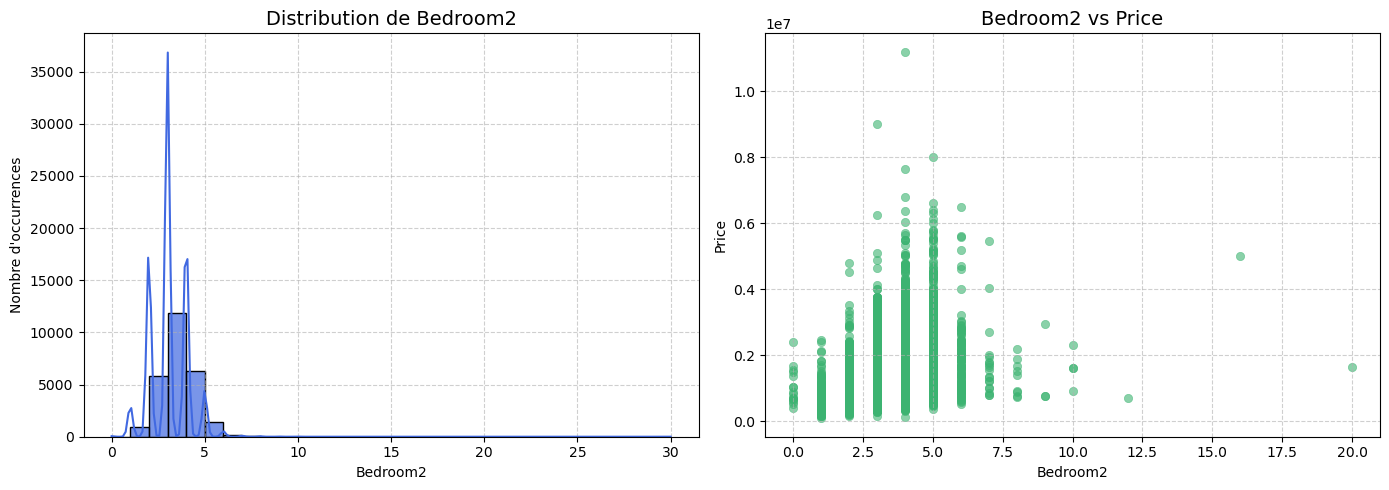

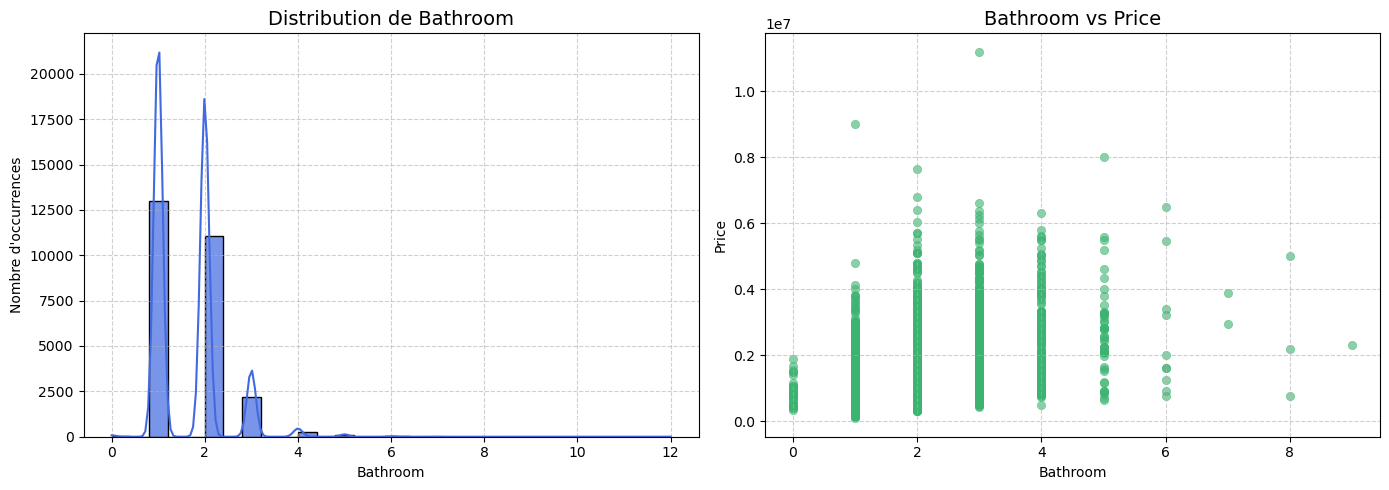

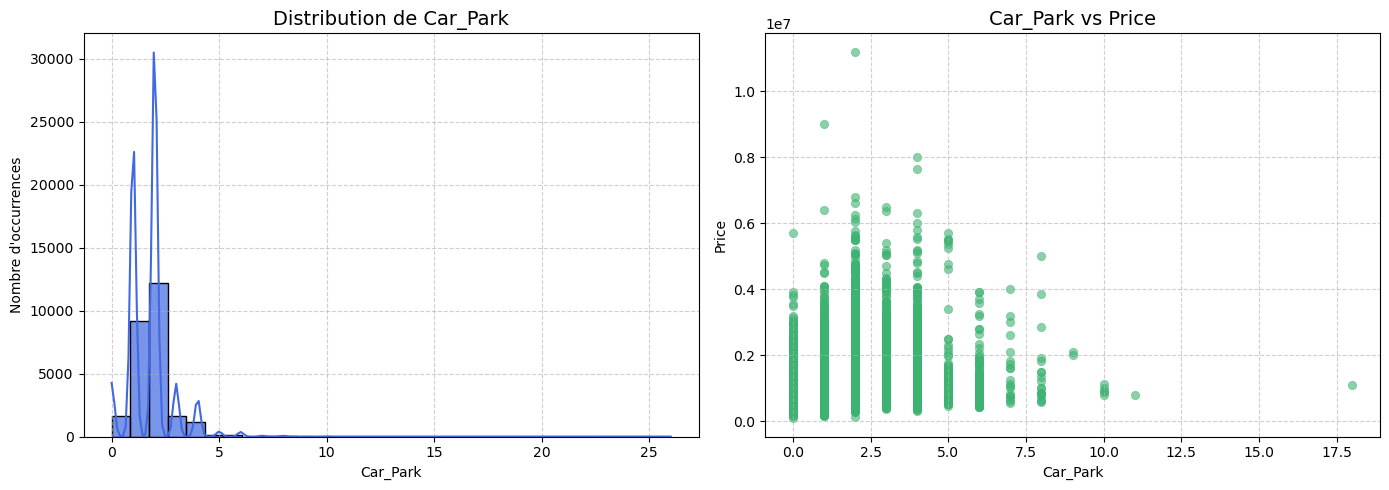

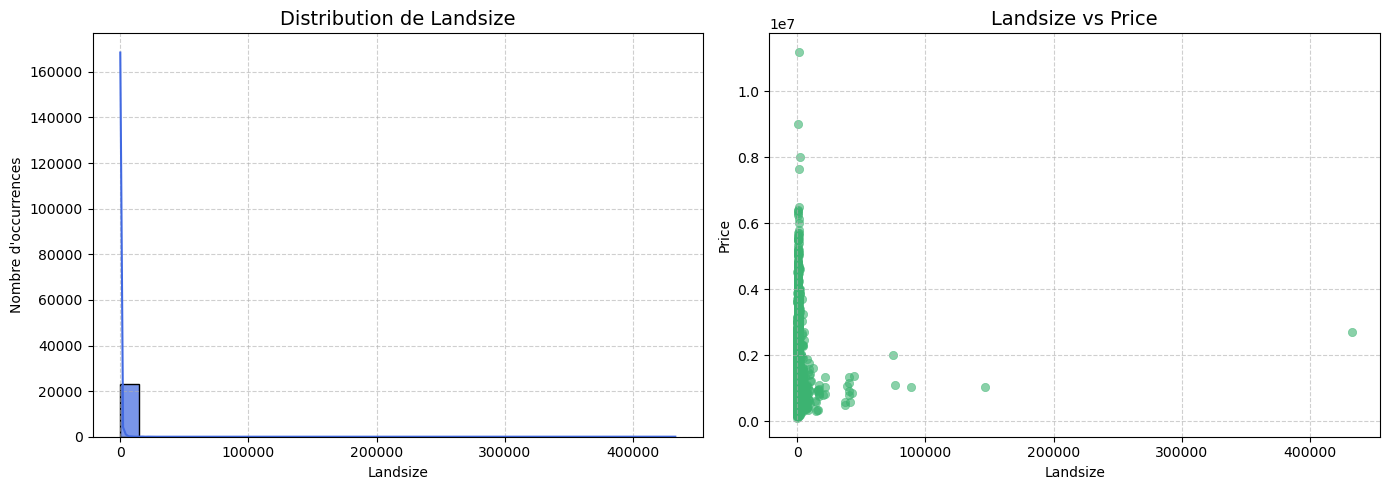

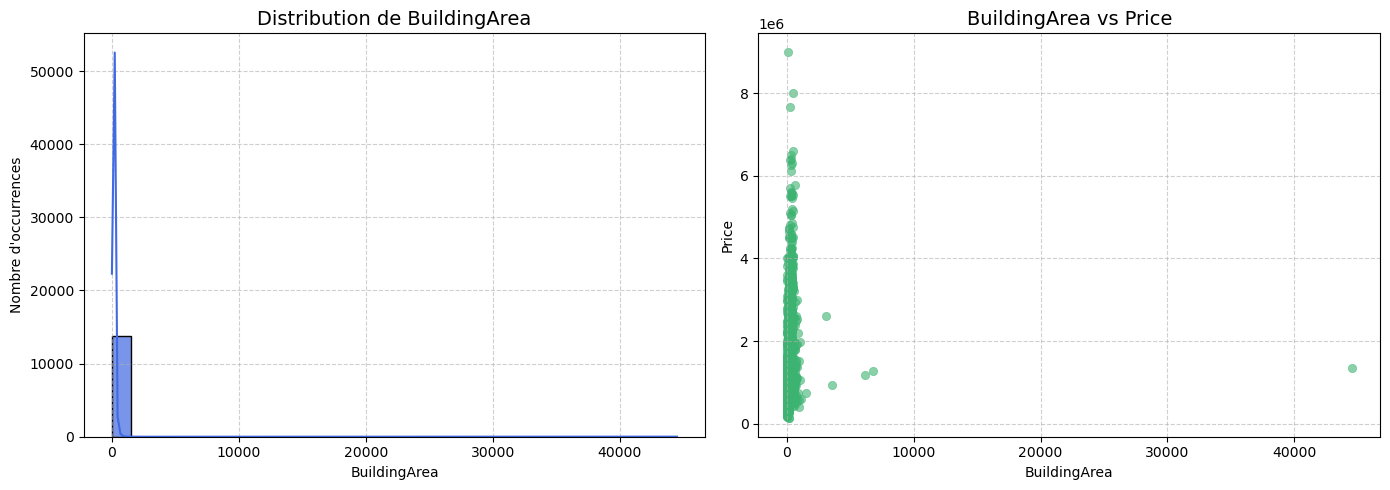

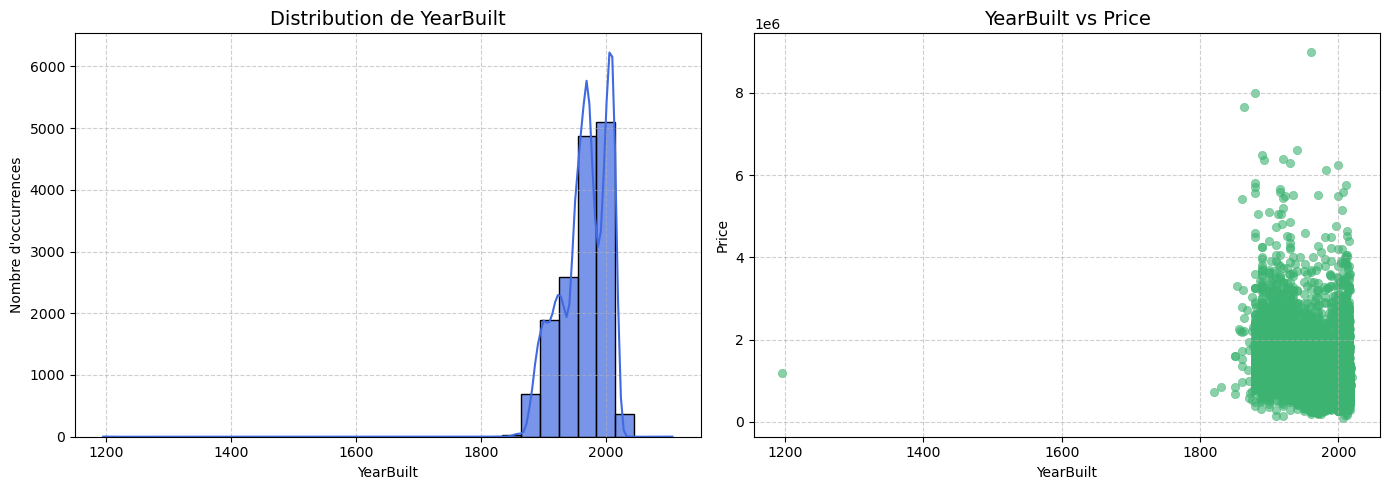

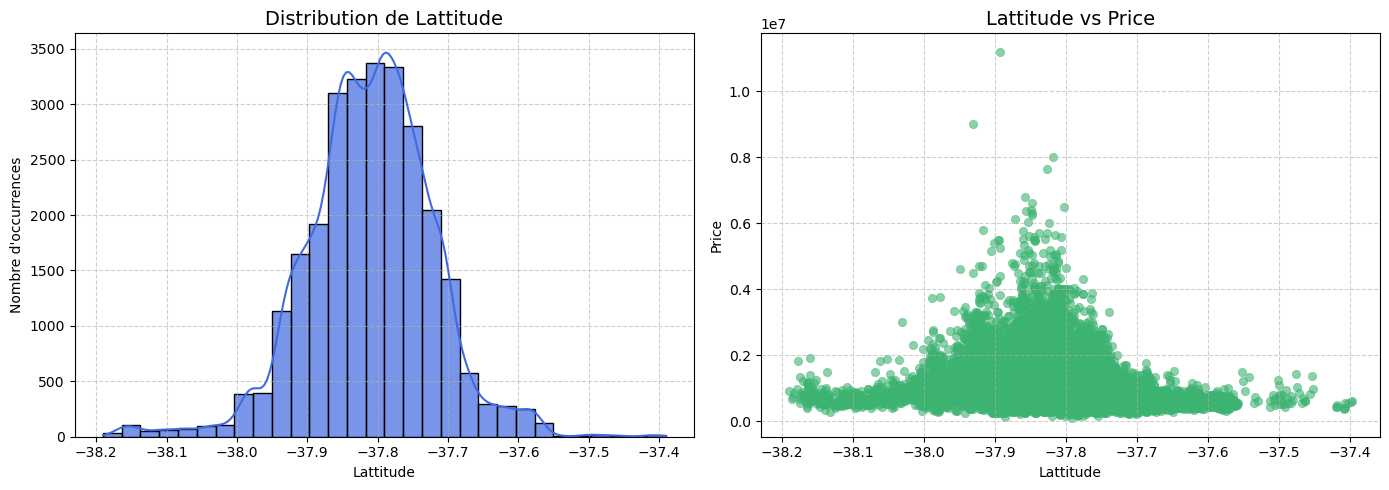

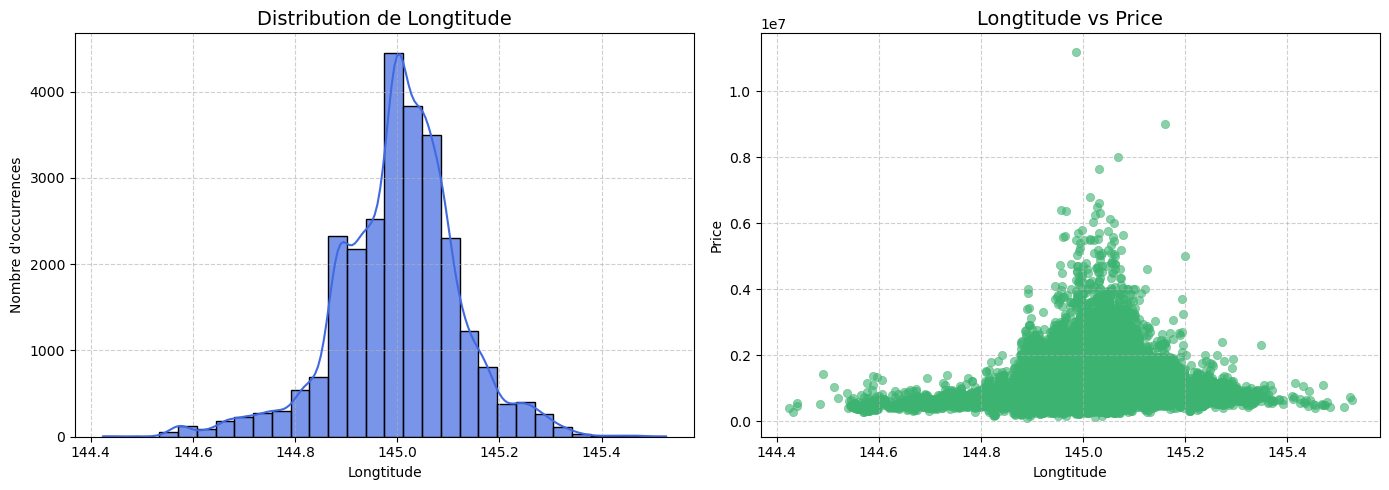

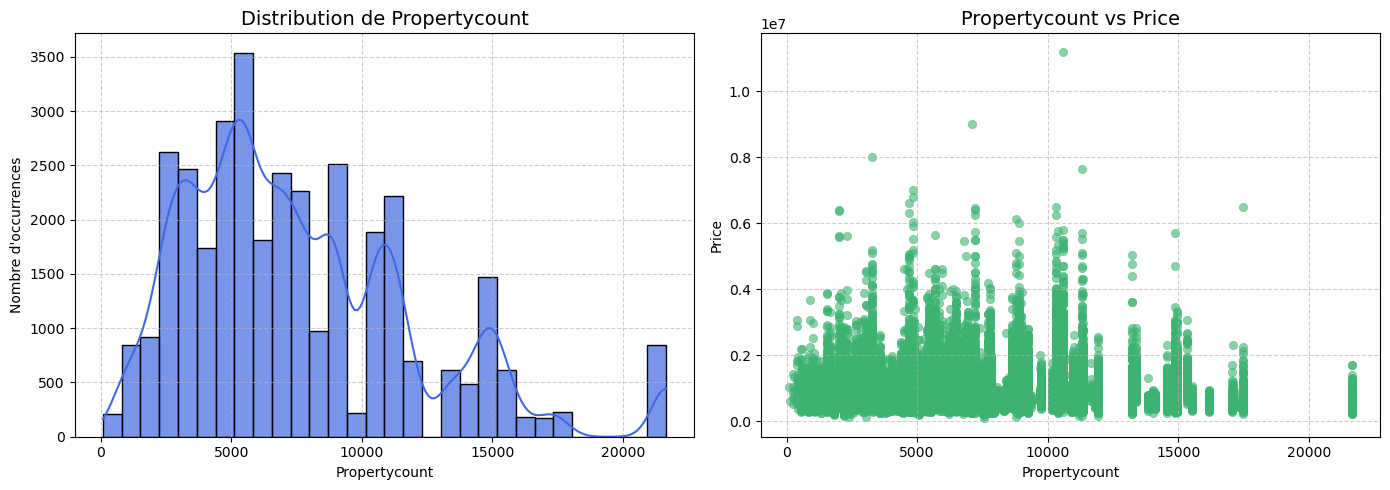

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Liste des colonnes à considérer
selected_columns = ['Rooms', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car_Park',
                    'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Propertycount']

# Vérifier la présence des colonnes dans le DataFrame
selected_columns = [col for col in selected_columns if col in df.columns]

# Ne garder que les colonnes numériques
selected_columns = [col for col in selected_columns if pd.api.types.is_numeric_dtype(df[col])]

# Générer les visualisations combinées
for col in selected_columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Histogramme (distribution)
    sns.histplot(df[col], bins=30, kde=True, color="royalblue", alpha=0.7, ax=axes[0])
    axes[0].set_title(f"Distribution de {col}", fontsize=14)
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Nombre d'occurrences")
    axes[0].grid(True, linestyle="--", alpha=0.6)

    # Scatter plot (relation avec Price)
    sns.scatterplot(data=df, x=col, y='Price', alpha=0.6, color='mediumseagreen', edgecolor=None, ax=axes[1])
    axes[1].set_title(f"{col} vs Price", fontsize=14)
    axes[1].set_xlabel(col)
    axes[1].set_ylabel("Price")
    axes[1].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.savefig(f"{col}_combined_plot.png", dpi=300)
    plt.show()


In [12]:
# 1. Supprimer les lignes où 'Price' est manquant (et faire une copie explicite)
df = df.dropna(subset=['Price']).copy()

# 2. Remplacer les valeurs NaN des colonnes numériques par la médiane
num_cols = ['Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car_Park', 
            'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Propertycount']

for col in num_cols:
    median_value = df[col].median()
    df.loc[:, col] = df[col].fillna(median_value)

# 3. Remplacer les valeurs NaN des colonnes catégorielles par le mode
cat_cols = ['CouncilArea', 'Regionname']

for col in cat_cols:
    mode_value = df[col].mode()[0]
    df.loc[:, col] = df[col].fillna(mode_value)


In [15]:
print(df.isnull().sum())

Suburb           0
Address          0
Rooms            0
Type             0
Price            0
Method           0
SellerG          0
Date             0
Distance         0
Postcode         0
Bedroom2         0
Bathroom         0
Car_Park         0
Landsize         0
BuildingArea     0
YearBuilt        0
CouncilArea      0
Lattitude        0
Longtitude       0
Regionname       0
Propertycount    0
dtype: int64


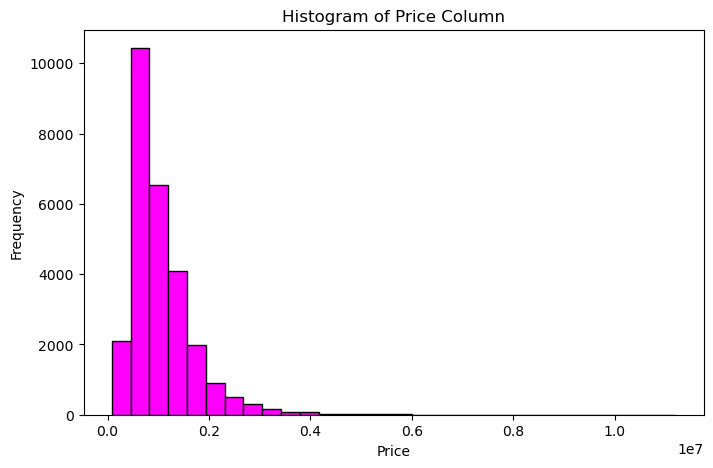

<Figure size 640x480 with 0 Axes>

In [17]:
# Tracer l'histogramme de la colonne 'Price'
plt.figure(figsize=(8,5))  # Définir la taille du graphique
plt.hist(df["Price"], bins=30, color="magenta", edgecolor="black")

# Ajouter un titre et des labels
plt.title("Histogram of Price Column")
plt.xlabel("Price")
plt.ylabel("Frequency")

# Afficher le graphique
plt.show()
plt.savefig('hist.png')

In [19]:
# Identifier automatiquement toutes les colonnes numériques
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

outliers_count = {}

# Boucle sur toutes les colonnes numériques
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Trouver les outliers
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    # Enregistrer le nombre d'outliers
    outliers_count[col] = outliers.shape[0]

# Afficher proprement
for col, count in outliers_count.items():
    print(f"Nombre d'outliers dans {col} : {count}")


Nombre d'outliers dans Rooms : 23
Nombre d'outliers dans Price : 1278
Nombre d'outliers dans Distance : 1188
Nombre d'outliers dans Postcode : 794
Nombre d'outliers dans Bedroom2 : 11390
Nombre d'outliers dans Bathroom : 238
Nombre d'outliers dans Car_Park : 1171
Nombre d'outliers dans Landsize : 992
Nombre d'outliers dans BuildingArea : 10576
Nombre d'outliers dans YearBuilt : 10890
Nombre d'outliers dans Lattitude : 1723
Nombre d'outliers dans Longtitude : 2210
Nombre d'outliers dans Propertycount : 727


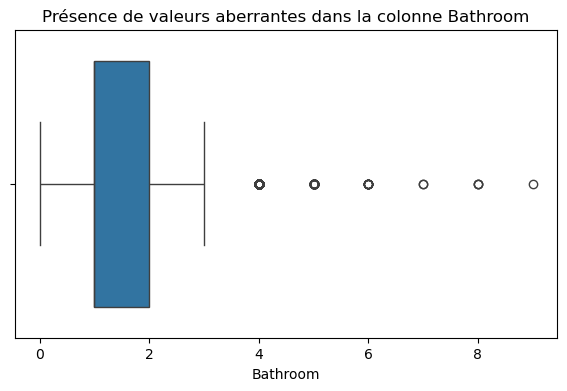

In [21]:
# 🔹 Tracer le boxplot pour la colonne 'Levy'
plt.figure(figsize=(7, 4))
sns.boxplot(x=df["Bathroom"])
plt.title("Présence de valeurs aberrantes dans la colonne Bathroom")
plt.xlabel("Bathroom")
plt.show()


In [23]:

def cap_outliers(df, col, lower_percentile=0.01, upper_percentile=0.99):
    lower_limit = df[col].quantile(lower_percentile)
    upper_limit = df[col].quantile(upper_percentile)
    df[col] = df[col].clip(lower=lower_limit, upper=upper_limit)

# Appliquer le capping sur certaines colonnes
cols_to_cap = ['Price', 'Landsize', 'BuildingArea', 'Distance', 'Bathroom', 'Bedroom2', 'Car_Park']

for col in cols_to_cap:
    cap_outliers(df, col)

In [25]:
# Fonction pour recalculer le nombre d'outliers après capping
def detect_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    return len(outliers)

# Recompter les outliers
for col in cols_to_cap:
    n_outliers = detect_outliers_iqr(df, col)
    print(f"Nombre d'outliers restants dans {col} : {n_outliers}")


Nombre d'outliers restants dans Price : 1278
Nombre d'outliers restants dans Landsize : 992
Nombre d'outliers restants dans BuildingArea : 10576
Nombre d'outliers restants dans Distance : 1188
Nombre d'outliers restants dans Bathroom : 0
Nombre d'outliers restants dans Bedroom2 : 11390
Nombre d'outliers restants dans Car_Park : 1171


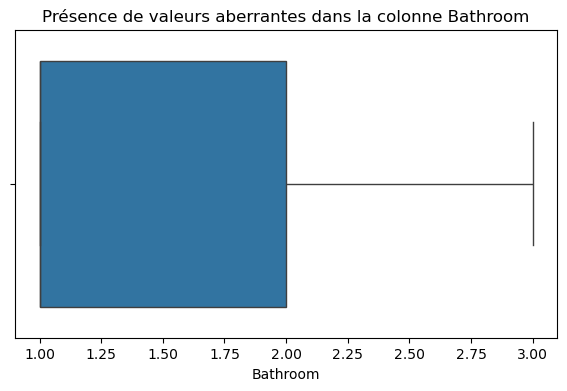

In [27]:
# 🔹 Tracer le boxplot pour la colonne 'Levy'
plt.figure(figsize=(7, 4))
sns.boxplot(x=df["Bathroom"])
plt.title("Présence de valeurs aberrantes dans la colonne Bathroom")
plt.xlabel("Bathroom")
plt.show()

                  Rooms     Price  Distance  Postcode  Bedroom2  Bathroom  \
Rooms          1.000000  0.480947  0.288272  0.081328  0.830878  0.530942   
Price          0.480947  1.000000 -0.223225  0.045114  0.404547  0.389707   
Distance       0.288272 -0.223225  1.000000  0.479105  0.264730  0.133265   
Postcode       0.081328  0.045114  0.479105  1.000000  0.081629  0.110335   
Bedroom2       0.830878  0.404547  0.264730  0.081629  1.000000  0.560146   
Bathroom       0.530942  0.389707  0.133265  0.110335  0.560146  1.000000   
Car_Park       0.330023  0.168133  0.218409  0.060136  0.408125  0.217373   
Landsize       0.269168  0.172439  0.243705  0.072129  0.315193  0.136308   
BuildingArea   0.450758  0.378054  0.121118  0.069985  0.512287  0.466541   
YearBuilt     -0.005738 -0.246042  0.219038  0.067811  0.004593  0.119591   
Lattitude      0.013910 -0.207462 -0.080878 -0.198737  0.019168 -0.053062   
Longtitude     0.072756  0.185576  0.172374  0.330332  0.090992  0.081975   

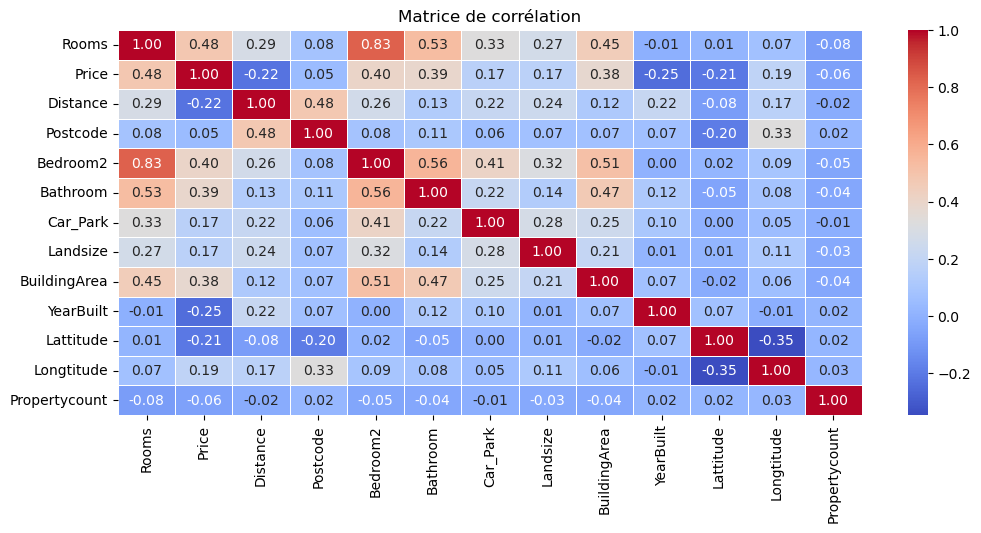

In [29]:
# Calcul de la matrice de corrélation en sélectionnant uniquement les colonnes numériques
correlation_matrix = df.select_dtypes(include=np.number).corr()

# Afficher la matrice de corrélation
print(correlation_matrix)

# Visualiser la matrice de corrélation sous forme de heatmap
plt.figure(figsize=(12, 5))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matrice de corrélation')
plt.show()

In [30]:
df = df.drop(columns=['Address'])

In [33]:
df['Rooms_per_Bathroom'] = df['Rooms'] / (df['Bathroom'] + 1)
df['Area_per_Room'] = df['BuildingArea'] / (df['Rooms'] + 1)

In [35]:
df['Age'] = 2024 - df['YearBuilt']

In [37]:
df['RoomPerBedroom'] = df['Rooms'] / (df['Bedroom2'] + 1)
df['HouseAreaRatio'] = df['BuildingArea'] / (df['Landsize'] + 1)
df['PricePerSqm'] = df['Price'] / (df['BuildingArea'] + 1)

# ➕ Densité de propriétés par code postal
df['PropertyDensity'] = df.groupby('Postcode')['Postcode'].transform('count')



# ➕ Age du bien
df['YearBuilt'] = pd.to_numeric(df['Age'], errors='coerce')
df['PropertyAge'] = df['Age'] - df['YearBuilt']
df['PropertyAge'] = df['PropertyAge'].replace([np.inf, -np.inf], np.nan)


In [39]:
df

,Suburb,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,...,Regionname,Propertycount,Rooms_per_Bathroom,Area_per_Room,Age,RoomPerBedroom,HouseAreaRatio,PricePerSqm,PropertyDensity,PropertyAge
1,Abbotsford,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,...,Northern Metropolitan,4019.0,1.000000,44.333333,54.0,0.666667,0.655172,11044.776119,102,0.0
2,Abbotsford,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,...,Northern Metropolitan,4019.0,1.000000,26.333333,124.0,0.666667,0.503185,12937.500000,102,0.0
4,Abbotsford,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,...,Northern Metropolitan,4019.0,1.000000,37.500000,124.0,0.750000,1.111111,9701.986755,102,0.0
5,Abbotsford,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,...,Northern Metropolitan,4019.0,1.000000,33.250000,54.0,0.750000,1.400000,6343.283582,102,0.0
6,Abbotsford,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,...,Northern Metropolitan,4019.0,2.000000,28.400000,10.0,1.000000,1.173554,11188.811189,102,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34852,Yarraville,4,h,1480000.0,PI,Jas,24/02/2018,6.3,3013.0,4.0,...,Western Metropolitan,6543.0,2.000000,26.600000,54.0,0.800000,0.223906,11044.776119,250,0.0
34853,Yarraville,2,h,888000.0,SP,Sweeney,24/02/2018,6.3,3013.0,2.0,...,Western Metropolitan,6543.0,0.666667,34.666667,6.0,0.666667,1.050505,8457.142857,250,0.0
34854,Yarraville,2,t,705000.0,S,Jas,24/02/2018,6.3,3013.0,2.0,...,Western Metropolitan,6543.0,1.000000,40.000000,24.0,0.666667,0.542986,5826.446281,250,0.0
34855,Yarraville,3,h,1140000.0,SP,hockingstuart,24/02/2018,6.3,3013.0,3.0,...,Western Metropolitan,6543.0,1.500000,33.250000,54.0,0.750000,0.259259,8507.462687,250,0.0


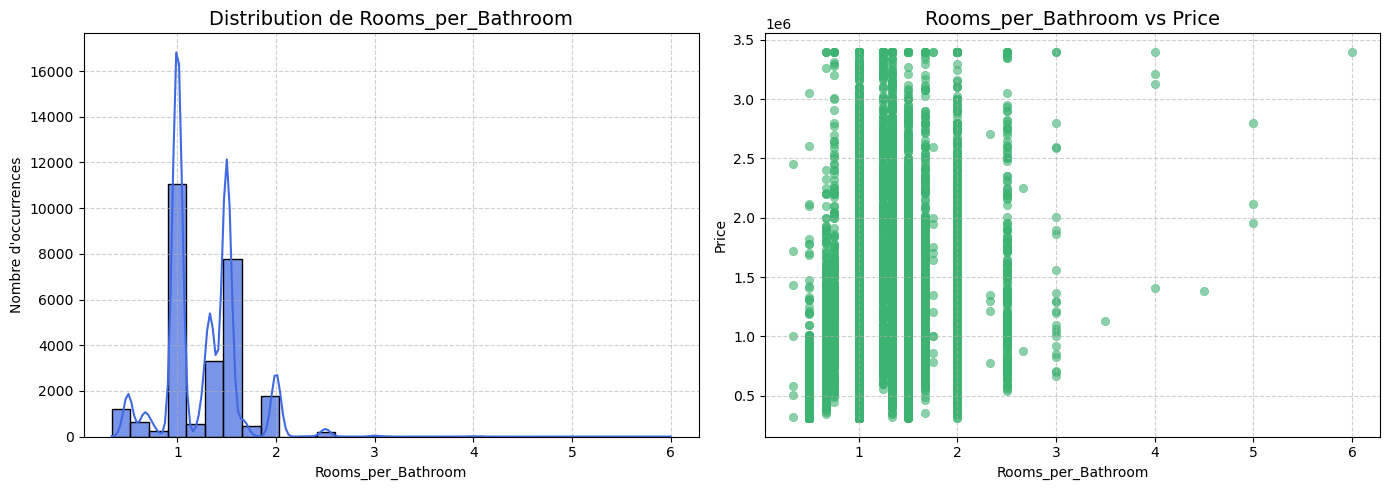

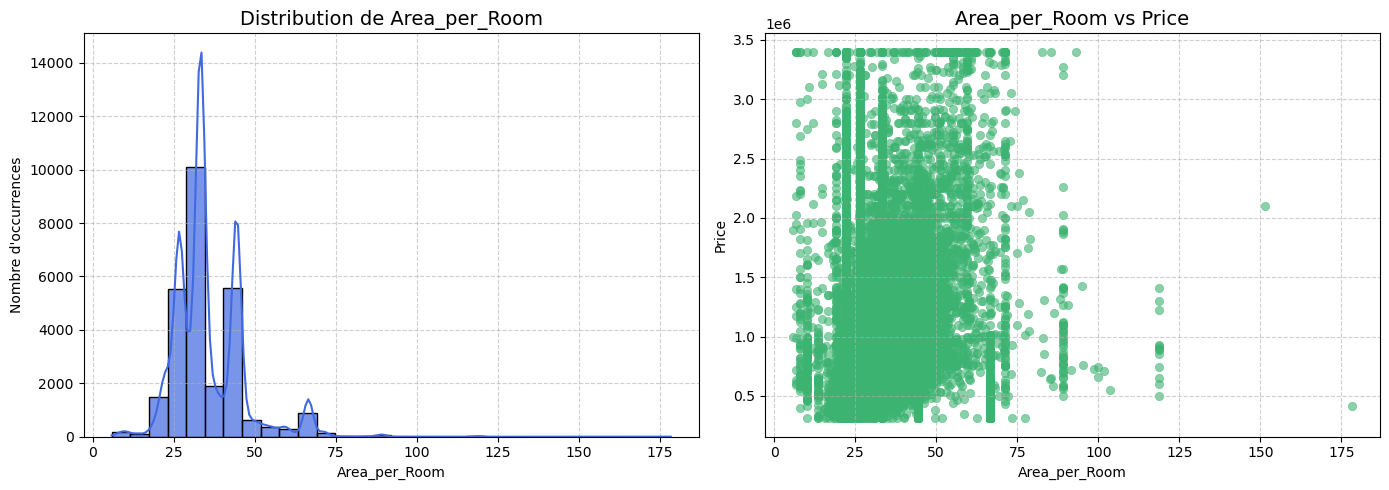

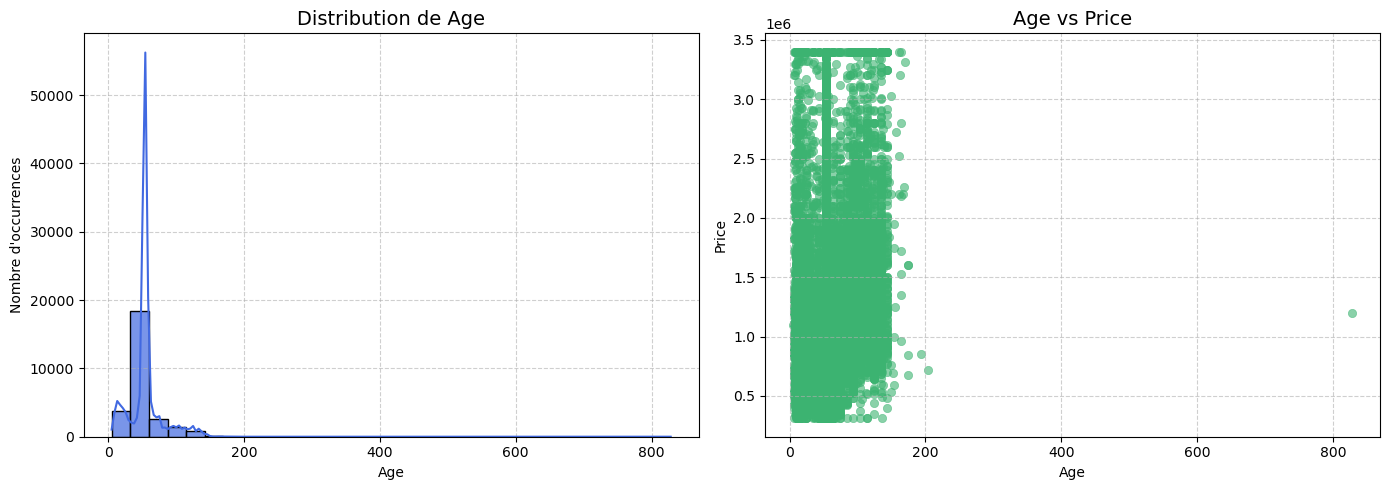

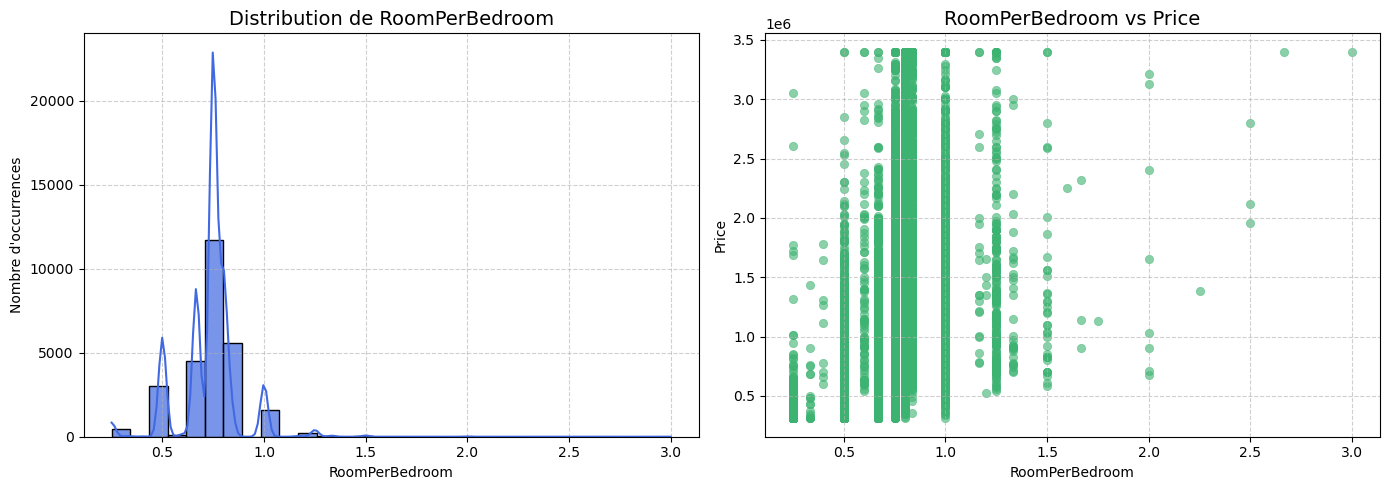

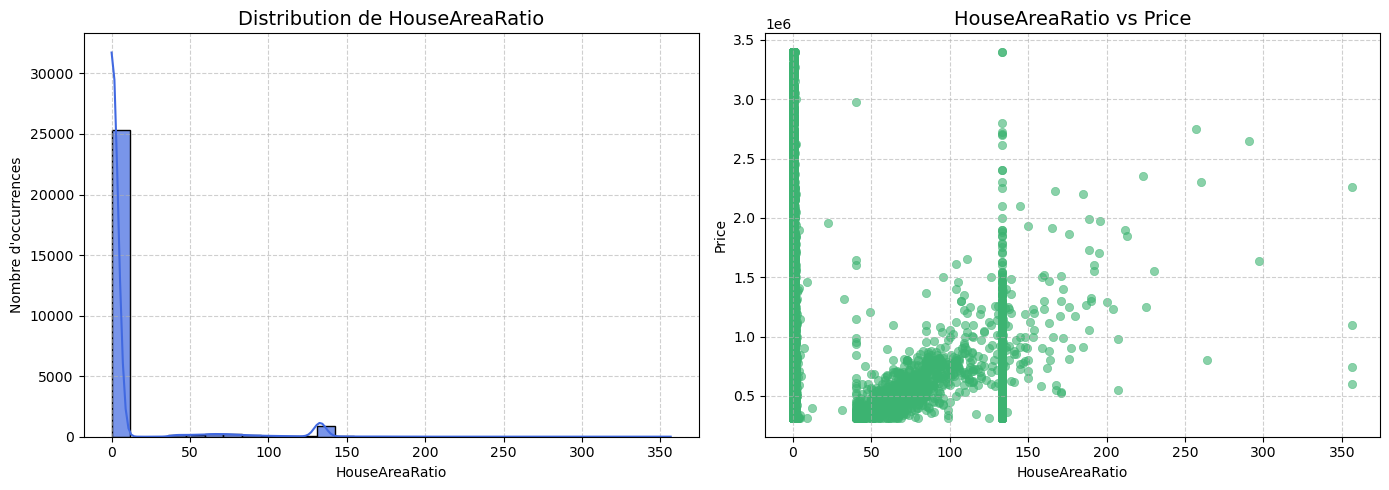

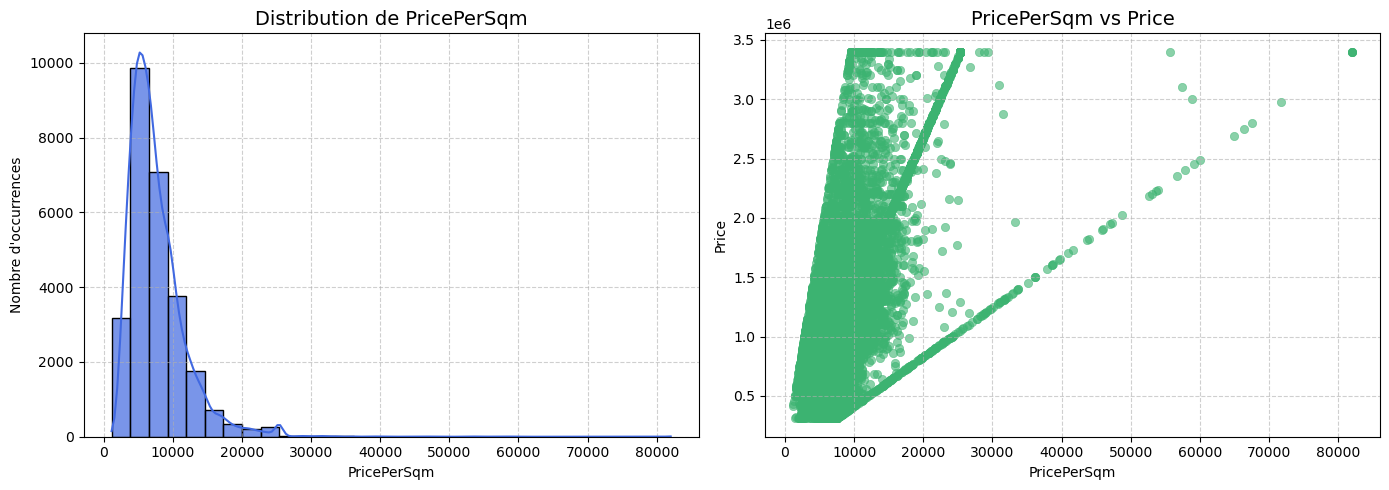

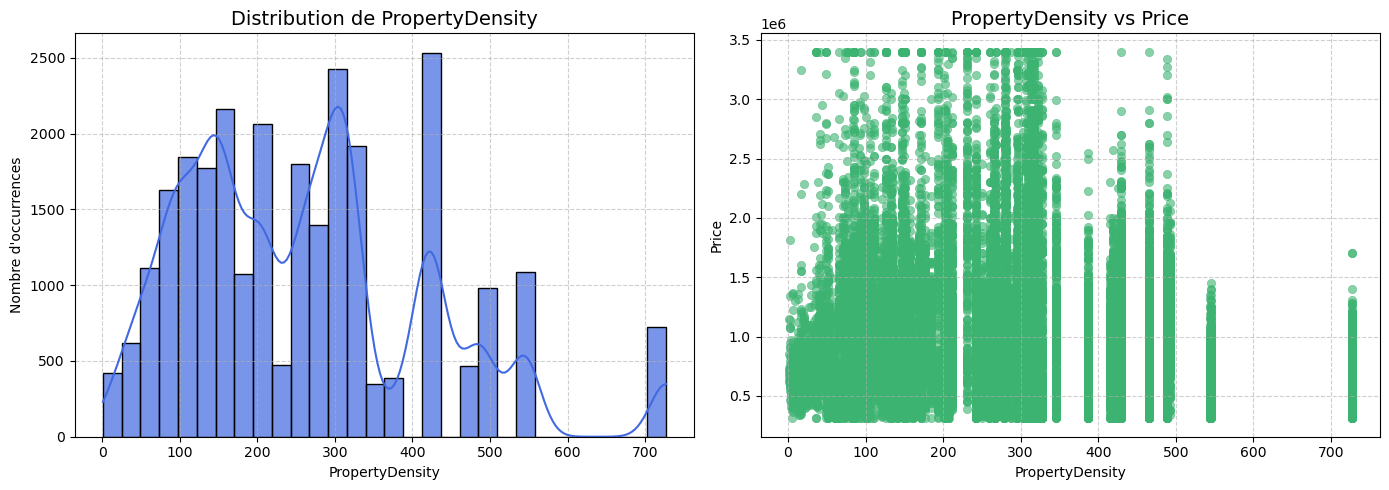

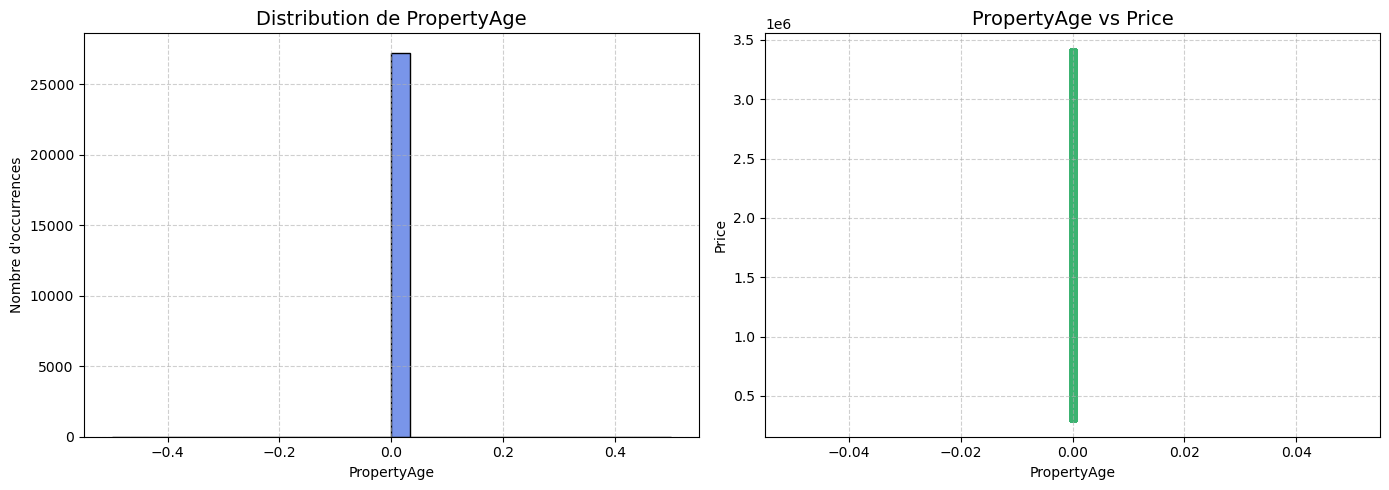

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Liste des colonnes à considérer
selected_columns = ['Rooms_per_Bathroom','Area_per_Room','Age','RoomPerBedroom','HouseAreaRatio','PricePerSqm','PropertyDensity','PropertyAge'
]

# Vérifier la présence des colonnes dans le DataFrame
selected_columns = [col for col in selected_columns if col in df.columns]

# Ne garder que les colonnes numériques
selected_columns = [col for col in selected_columns if pd.api.types.is_numeric_dtype(df[col])]

# Générer les visualisations combinées
for col in selected_columns:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Histogramme (distribution)
    sns.histplot(df[col], bins=30, kde=True, color="royalblue", alpha=0.7, ax=axes[0])
    axes[0].set_title(f"Distribution de {col}", fontsize=14)
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Nombre d'occurrences")
    axes[0].grid(True, linestyle="--", alpha=0.6)

    # Scatter plot (relation avec Price)
    sns.scatterplot(data=df, x=col, y='Price', alpha=0.6, color='mediumseagreen', edgecolor=None, ax=axes[1])
    axes[1].set_title(f"{col} vs Price", fontsize=14)
    axes[1].set_xlabel(col)
    axes[1].set_ylabel("Price")
    axes[1].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.savefig(f"{col}_combined_plot.png", dpi=300)
    plt.show()


C:\Users\DELL\AppData\Local\Temp\ipykernel_704\1019557932.py:38: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('tab20', len(features))


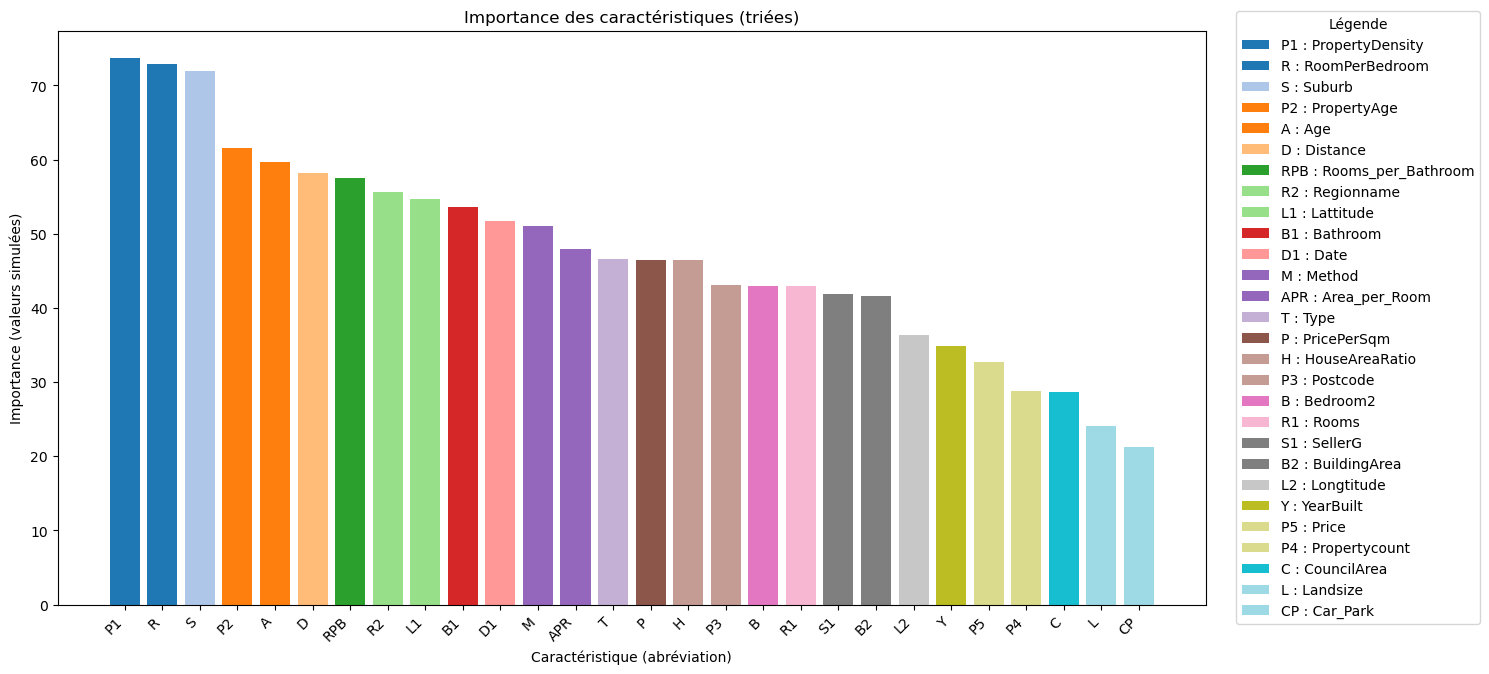

In [42]:
import matplotlib.pyplot as plt
import numpy as np

# Liste des caractéristiques
features = ['Rooms_per_Bathroom','Area_per_Room','Age','RoomPerBedroom','HouseAreaRatio','PricePerSqm','PropertyDensity','PropertyAge',
'Rooms', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car_Park',
                    'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Propertycount',
                    'Suburb','Type','Method','CouncilArea','SellerG','Date','Price','Regionname']

# Créer des abréviations uniques
def abbreviate_unique(features):
    abbr_map = {}
    unique_abbr = []
    for feature in features:
        parts = feature.replace('_', ' ').split()
        abbr = ''.join([word[0].upper() for word in parts])
        if abbr in abbr_map:
            abbr_map[abbr] += 1
            abbr = f"{abbr}{abbr_map[abbr]}"
        else:
            abbr_map[abbr] = 0
        unique_abbr.append(abbr)
    return unique_abbr

abbreviations = abbreviate_unique(features)

# Générer des importances simulées
np.random.seed(42)
importances = np.abs(np.random.normal(50, 15, size=len(features)))

# Trier par importance décroissante
sorted_indices = np.argsort(importances)[::-1]
importances = importances[sorted_indices]
features = [features[i] for i in sorted_indices]
abbreviations = [abbreviations[i] for i in sorted_indices]

# Créer le colormap
colors = plt.cm.get_cmap('tab20', len(features))
color_list = [colors(i) for i in range(len(features))]

# Tracer le graphique
fig, ax = plt.subplots(figsize=(15, 7))
bars = ax.bar(abbreviations, importances, color=color_list)

# Légende
legend_labels = [f"{abbr} : {feat}" for abbr, feat in zip(abbreviations, features)]
ax.legend(bars, legend_labels, loc='center left', bbox_to_anchor=(1.02, 0.5), title="Légende")

# Titres et axes
ax.set_title("Importance des caractéristiques (triées)")
ax.set_xlabel("Caractéristique (abréviation)")
ax.set_ylabel("Importance (valeurs simulées)")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [43]:
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder
from category_encoders import TargetEncoder

def smart_numeric_encoding(df, target_column, onehot_threshold=10):
    df_encoded = df.copy()

    categorical_cols = df_encoded.select_dtypes(include='object').columns.tolist()
    if target_column in categorical_cols:
        categorical_cols.remove(target_column)

    # Séparation selon cardinalité
    ordinal_cols = [col for col in categorical_cols if df_encoded[col].nunique() <= onehot_threshold]
    targetenc_cols = [col for col in categorical_cols if df_encoded[col].nunique() > onehot_threshold]

    # Encodage ordinal (numérique unique par catégorie)
    if ordinal_cols:
        print("OrdinalEncoding on:", ordinal_cols)
        encoder = OrdinalEncoder()
        df_encoded[ordinal_cols] = encoder.fit_transform(df_encoded[ordinal_cols])

    # Target Encoding
    if targetenc_cols:
        print("TargetEncoding on:", targetenc_cols)
        encoder = TargetEncoder(cols=targetenc_cols)
        df_encoded[targetenc_cols] = encoder.fit_transform(df_encoded[targetenc_cols], df_encoded[target_column])

    return df_encoded

In [44]:
df_encoded = smart_numeric_encoding(df, target_column='Price', onehot_threshold=10)

OrdinalEncoding on: ['Type', 'Method', 'Regionname']
TargetEncoding on: ['Suburb', 'SellerG', 'Date', 'CouncilArea']


In [45]:
df_encoded = df_encoded.drop(columns=['PropertyAge'])

In [46]:
df_encoded

,Suburb,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,...,Longtitude,Regionname,Propertycount,Rooms_per_Bathroom,Area_per_Room,Age,RoomPerBedroom,HouseAreaRatio,PricePerSqm,PropertyDensity
1,1.033649e+06,2,0.0,1480000.0,1.0,9.992356e+05,1.172947e+06,2.5,3067.0,2.0,...,144.99840,2.0,4019.0,1.000000,44.333333,54.0,0.666667,0.655172,11044.776119,102
2,1.033649e+06,2,0.0,1035000.0,1.0,9.992356e+05,9.299441e+05,2.5,3067.0,2.0,...,144.99340,2.0,4019.0,1.000000,26.333333,124.0,0.666667,0.503185,12937.500000,102
4,1.033649e+06,3,0.0,1465000.0,3.0,9.992356e+05,1.129943e+06,2.5,3067.0,3.0,...,144.99440,2.0,4019.0,1.000000,37.500000,124.0,0.750000,1.111111,9701.986755,102
5,1.033649e+06,3,0.0,850000.0,0.0,9.992356e+05,1.129943e+06,2.5,3067.0,3.0,...,144.99690,2.0,4019.0,1.000000,33.250000,54.0,0.750000,1.400000,6343.283582,102
6,1.033649e+06,4,0.0,1600000.0,4.0,1.018226e+06,1.050940e+06,2.5,3067.0,3.0,...,144.99410,2.0,4019.0,2.000000,28.400000,10.0,1.000000,1.173554,11188.811189,102
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34852,9.912450e+05,4,0.0,1480000.0,0.0,8.706340e+05,1.089004e+06,6.3,3013.0,4.0,...,144.88467,6.0,6543.0,2.000000,26.600000,54.0,0.800000,0.223906,11044.776119,250
34853,9.912450e+05,2,0.0,888000.0,3.0,8.269090e+05,1.089004e+06,6.3,3013.0,2.0,...,144.88826,6.0,6543.0,0.666667,34.666667,6.0,0.666667,1.050505,8457.142857,250
34854,9.912450e+05,2,1.0,705000.0,1.0,8.706340e+05,1.089004e+06,6.3,3013.0,2.0,...,144.87856,6.0,6543.0,1.000000,40.000000,24.0,0.666667,0.542986,5826.446281,250
34855,9.912450e+05,3,0.0,1140000.0,3.0,9.295657e+05,1.089004e+06,6.3,3013.0,3.0,...,145.00320,6.0,6543.0,1.500000,33.250000,54.0,0.750000,0.259259,8507.462687,250


In [47]:
from sklearn.preprocessing import StandardScaler

# Identifier les colonnes numériques
num_cols = df_encoded.select_dtypes(include=['float64', 'int64']).columns

# Initialiser le scaler
scaler = StandardScaler()

# Appliquer la standardisation aux colonnes numériques
df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])




In [48]:
print(df_encoded)

         Suburb     Rooms      Type     Price    Method   SellerG      Date  \
1     -0.046809 -1.039292 -0.652474  0.747630 -0.386339 -0.163802  1.473634   
2     -0.046809 -1.039292 -0.652474 -0.009775 -0.386339 -0.163802 -1.240519   
4     -0.046809  0.008072 -0.652474  0.722099  1.340319 -0.163802  0.993311   
5     -0.046809  0.008072 -0.652474 -0.324652 -1.249667 -0.163802  0.993311   
6     -0.046809  1.055436 -0.652474  0.951874  2.203647 -0.096502  0.110906   
...         ...       ...       ...       ...       ...       ...       ...   
34852 -0.170835  1.055436 -0.652474  0.747630 -1.249667 -0.619543  0.536058   
34853 -0.170835 -1.039292 -0.652474 -0.259974  1.340319 -0.774496  0.536058   
34854 -0.170835 -1.039292  0.558229 -0.571447 -0.386339 -0.619543  0.536058   
34855 -0.170835  0.008072 -0.652474  0.168938  1.340319 -0.410699  0.536058   
34856 -0.170835 -1.039292 -0.652474 -0.035306 -1.249667 -0.902344  0.536058   

       Distance  Postcode  Bedroom2  ...  Longtitud

In [49]:
df_encoded

,Suburb,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,...,Longtitude,Regionname,Propertycount,Rooms_per_Bathroom,Area_per_Room,Age,RoomPerBedroom,HouseAreaRatio,PricePerSqm,PropertyDensity
1,-0.046809,-1.039292,-0.652474,0.747630,-0.386339,-0.163802,1.473634,-1.326774,-0.421063,-1.294444,...,0.001883,-0.81167,-0.789764,-0.667035,0.792567,-0.061283,-0.457845,-0.248112,0.769364,-1.018559
2,-0.046809,-1.039292,-0.652474,-0.009775,-0.386339,-0.163802,-1.240519,-1.326774,-0.421063,-1.294444,...,-0.045304,-0.81167,-0.789764,-0.667035,-0.866765,2.791316,-0.457845,-0.253356,1.203281,-1.018559
4,-0.046809,0.008072,-0.652474,0.722099,1.340319,-0.163802,0.993311,-1.326774,-0.421063,-0.034136,...,-0.035866,-0.81167,-0.789764,-0.667035,0.162635,2.791316,0.120827,-0.232381,0.461523,-1.018559
5,-0.046809,0.008072,-0.652474,-0.324652,-1.249667,-0.163802,0.993311,-1.326774,-0.421063,-0.034136,...,-0.012273,-0.81167,-0.789764,-0.667035,-0.229151,-0.061283,0.120827,-0.222413,-0.308476,-1.018559
6,-0.046809,1.055436,-0.652474,0.951874,2.203647,-0.096502,0.110906,-1.326774,-0.421063,-0.034136,...,-0.038697,-0.81167,-0.789764,2.023886,-0.676249,-1.854346,1.856843,-0.230226,0.802385,-1.018559
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34852,-0.170835,1.055436,-0.652474,0.747630,-1.249667,-0.619543,0.536058,-0.749864,-0.906955,1.226171,...,-1.071431,1.13431,-0.227884,2.023886,-0.842182,-0.061283,0.468031,-0.262991,0.769364,-0.070178
34853,-0.170835,-1.039292,-0.652474,-0.259974,1.340319,-0.774496,0.536058,-0.749864,-0.906955,-1.294444,...,-1.037551,1.13431,-0.227884,-1.564009,-0.098556,-2.017351,-0.457845,-0.234472,0.176137,-0.070178
34854,-0.170835,-1.039292,0.558229,-0.571447,-0.386339,-0.619543,0.536058,-0.749864,-0.906955,-1.294444,...,-1.129094,1.13431,-0.227884,-0.667035,0.393098,-1.283826,-0.457845,-0.251982,-0.426964,-0.070178
34855,-0.170835,0.008072,-0.652474,0.168938,1.340319,-0.410699,0.536058,-0.749864,-0.906955,-0.034136,...,0.047183,1.13431,-0.227884,0.678425,-0.229151,-0.061283,0.120827,-0.261772,0.187673,-0.070178


In [59]:
# Séparer les variables indépendantes (X) de la variable cible (y)
X = df_encoded.drop(columns=['Price'])  # 'Price' est la variable cible
y = df_encoded['Price']  # C'est la colonne qu'on veut prédire

In [61]:
X

,Suburb,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,...,Longtitude,Regionname,Propertycount,Rooms_per_Bathroom,Area_per_Room,Age,RoomPerBedroom,HouseAreaRatio,PricePerSqm,PropertyDensity
1,-0.046809,-1.039292,-0.652474,-0.386339,-0.163802,1.473634,-1.326774,-0.421063,-1.294444,-0.718312,...,0.001883,-0.81167,-0.789764,-0.667035,0.792567,-0.061283,-0.457845,-0.248112,0.769364,-1.018559
2,-0.046809,-1.039292,-0.652474,-0.386339,-0.163802,-1.240519,-1.326774,-0.421063,-1.294444,-0.718312,...,-0.045304,-0.81167,-0.789764,-0.667035,-0.866765,2.791316,-0.457845,-0.253356,1.203281,-1.018559
4,-0.046809,0.008072,-0.652474,1.340319,-0.163802,0.993311,-1.326774,-0.421063,-0.034136,0.910775,...,-0.035866,-0.81167,-0.789764,-0.667035,0.162635,2.791316,0.120827,-0.232381,0.461523,-1.018559
5,-0.046809,0.008072,-0.652474,-1.249667,-0.163802,0.993311,-1.326774,-0.421063,-0.034136,0.910775,...,-0.012273,-0.81167,-0.789764,-0.667035,-0.229151,-0.061283,0.120827,-0.222413,-0.308476,-1.018559
6,-0.046809,1.055436,-0.652474,2.203647,-0.096502,0.110906,-1.326774,-0.421063,-0.034136,-0.718312,...,-0.038697,-0.81167,-0.789764,2.023886,-0.676249,-1.854346,1.856843,-0.230226,0.802385,-1.018559
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34852,-0.170835,1.055436,-0.652474,-1.249667,-0.619543,0.536058,-0.749864,-0.906955,1.226171,-0.718312,...,-1.071431,1.13431,-0.227884,2.023886,-0.842182,-0.061283,0.468031,-0.262991,0.769364,-0.070178
34853,-0.170835,-1.039292,-0.652474,1.340319,-0.774496,0.536058,-0.749864,-0.906955,-1.294444,0.910775,...,-1.037551,1.13431,-0.227884,-1.564009,-0.098556,-2.017351,-0.457845,-0.234472,0.176137,-0.070178
34854,-0.170835,-1.039292,0.558229,-0.386339,-0.619543,0.536058,-0.749864,-0.906955,-1.294444,-0.718312,...,-1.129094,1.13431,-0.227884,-0.667035,0.393098,-1.283826,-0.457845,-0.251982,-0.426964,-0.070178
34855,-0.170835,0.008072,-0.652474,1.340319,-0.410699,0.536058,-0.749864,-0.906955,-0.034136,-0.718312,...,0.047183,1.13431,-0.227884,0.678425,-0.229151,-0.061283,0.120827,-0.261772,0.187673,-0.070178


In [63]:
from sklearn.model_selection import train_test_split

# Séparer les données en jeux d'entraînement (80%) et de test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [65]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam,Adadelta,Adagrad,Nadam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import backend as K

ImportError: Traceback (most recent call last):
  File "C:\Users\DELL\anaconda3\Lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 73, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: Une routine d’initialisation d’une bibliothèque de liens dynamiques (DLL) a échoué.


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.

In [ ]:
# R² personnalisé
def r2_score(y_true, y_pred):
    ss_res = K.sum(K.square(y_true - y_pred))
    ss_tot = K.sum(K.square(y_true - K.mean(y_true)))
    return 1 - ss_res / (ss_tot + K.epsilon())


MAE: 0.014235361075366729
MSE: 0.0042918623223414
R2: 0.9956441898438275
Train MAE: 0.007290900048854504
Train MSE: 0.00016215321177899365
Train R2: 0.9998384398102859


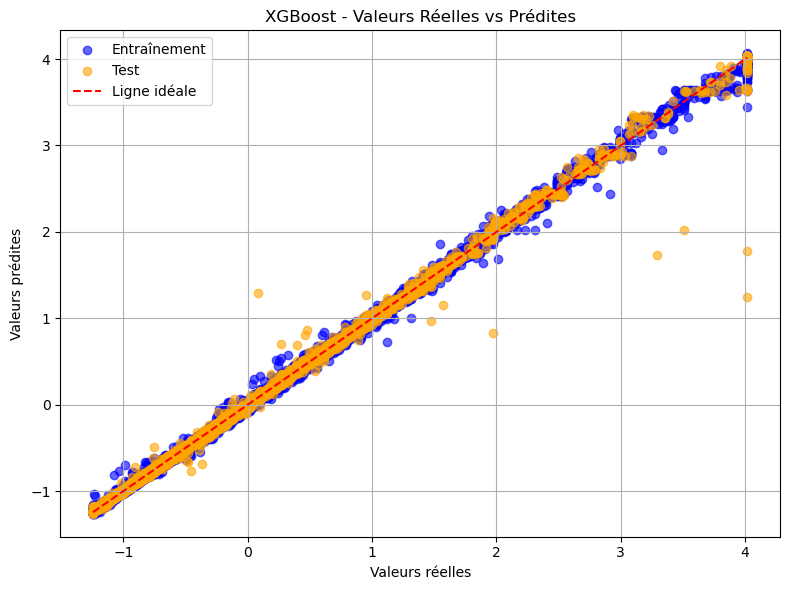

In [84]:
import xgboost as xgb
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Créer et entraîner le modèle XGBoost
model_xgb = xgb.XGBRegressor(n_estimators=300, max_depth=7, learning_rate=0.05)
model_xgb.fit(X_train, y_train)
# Faire des prédictions
y_pred = model_xgb.predict(X_test)

# Calculer les métriques
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae}")
print(f"MSE: {mse}")
print(f"R2: {r2}")
# Faire des prédictions sur l'ensemble d'entraînement
y_pred_train = model_xgb.predict(X_train)

# Calculer les métriques de performance pour l'ensemble d'entraînement
mae_train = mean_absolute_error(y_train, y_pred_train)
mse_train = mean_squared_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

# Afficher les résultats pour l'ensemble d'entraînement
print(f"Train MAE: {mae_train}")
print(f"Train MSE: {mse_train}")
print(f"Train R2: {r2_train}")





# Graphique des prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color="blue", label="Entraînement", alpha=0.6)
plt.scatter(y_test, y_test_pred, color="orange", label="Test", alpha=0.6)
x_vals = np.linspace(min(min(y_train), min(y_test)), max(max(y_train), max(y_test)), 100)
plt.plot(x_vals, x_vals, 'r--', label="Ligne idéale")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("XGBoost - Valeurs Réelles vs Prédites")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

MAE Train: 0.018359235316976766
MSE Train: 0.0007096849007206017
R² Train: 0.9992929105384979
MAE Test: 0.023165086033395715
MSE Test: 0.0014242184261419478
R² Test: 0.9985545610228679


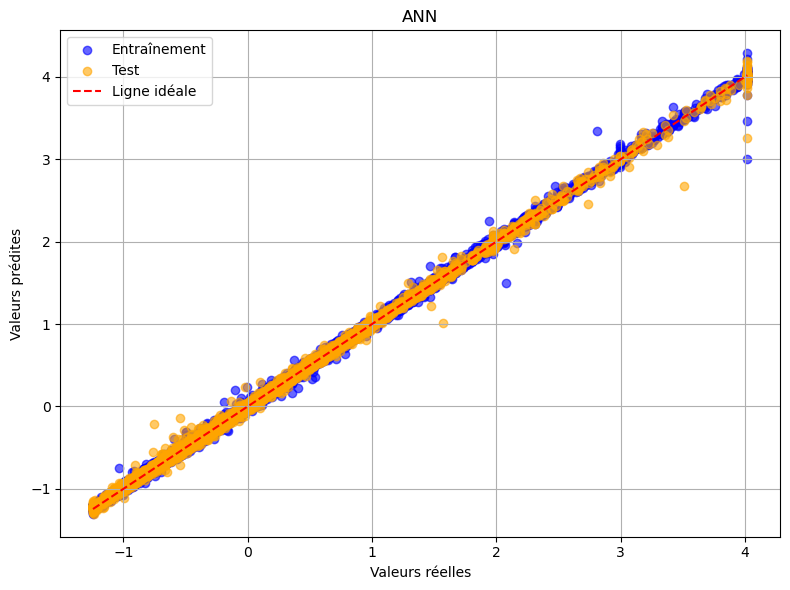

In [86]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Créer le modèle
mlp = MLPRegressor(hidden_layer_sizes=(128, 64),
                   activation='relu',
                   solver='adam',
                   alpha=0.0001,
                   learning_rate_init=0.001,
                   max_iter=500,
                   random_state=42,
                   early_stopping=True,
                   validation_fraction=0.2)

# Entraînement
mlp.fit(X_train, y_train)

# Prédictions
y_train_pred = mlp.predict(X_train)
y_test_pred = mlp.predict(X_test)

# Évaluation
print("MAE Train:", mean_absolute_error(y_train, y_train_pred))
print("MSE Train:", mean_squared_error(y_train, y_train_pred))
print("R² Train:", r2_score(y_train, y_train_pred))
print("MAE Test:", mean_absolute_error(y_test, y_test_pred))
print("MSE Test:", mean_squared_error(y_test, y_test_pred))
print("R² Test:", r2_score(y_test, y_test_pred))

# Graphique des prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color="blue", label="Entraînement", alpha=0.6)
plt.scatter(y_test, y_test_pred, color="orange", label="Test", alpha=0.6)
x_vals = np.linspace(min(min(y_train), min(y_test)), max(max(y_train), max(y_test)), 100)
plt.plot(x_vals, x_vals, 'r--', label="Ligne idéale")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("ANN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Train MAE: 0.005259147275655144
Train MSE: 7.288696299680637e-05
Train R2: 0.9999273795971091
Test MAE: 0.008907728816858869
Test MSE: 0.0011742990826154717
Test R2: 0.9988082041113449


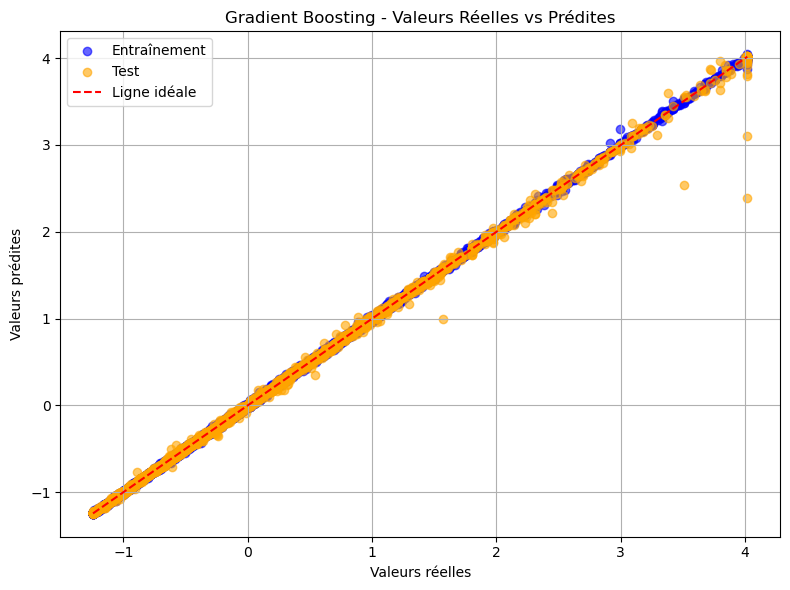

In [88]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Initialiser le modèle avec des hyperparamètres ajustés
gb = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.07,
    max_depth=7,
    min_samples_split=5,
    min_samples_leaf=5,
    subsample=0.9,
    random_state=42
)

# Entraîner le modèle
gb.fit(X_train, y_train)

# Faire des prédictions
y_train_pred = gb.predict(X_train)
y_test_pred = gb.predict(X_test)

# Calcul des métriques - Train
mae_train = mean_absolute_error(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
r2_train = r2_score(y_train, y_train_pred)

# Calcul des métriques - Test
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)

# Affichage des métriques
print(f"Train MAE: {mae_train}")
print(f"Train MSE: {mse_train}")
print(f"Train R2: {r2_train}")
print(f"Test MAE: {mae_test}")
print(f"Test MSE: {mse_test}")
print(f"Test R2: {r2_test}")

# Graphique des prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color="blue", label="Entraînement", alpha=0.6)
plt.scatter(y_test, y_test_pred, color="orange", label="Test", alpha=0.6)
x_vals = np.linspace(min(min(y_train), min(y_test)), max(max(y_train), max(y_test)), 100)
plt.plot(x_vals, x_vals, 'r--', label="Ligne idéale")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Gradient Boosting - Valeurs Réelles vs Prédites")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Train MAE: 0.19813515856401492
Train MSE: 0.08465753161772392
Train R2: 0.9156520754733596
Test MAE: 0.24357561142686068
Test MSE: 0.12516467603159087
Test R2: 0.8729703969732634


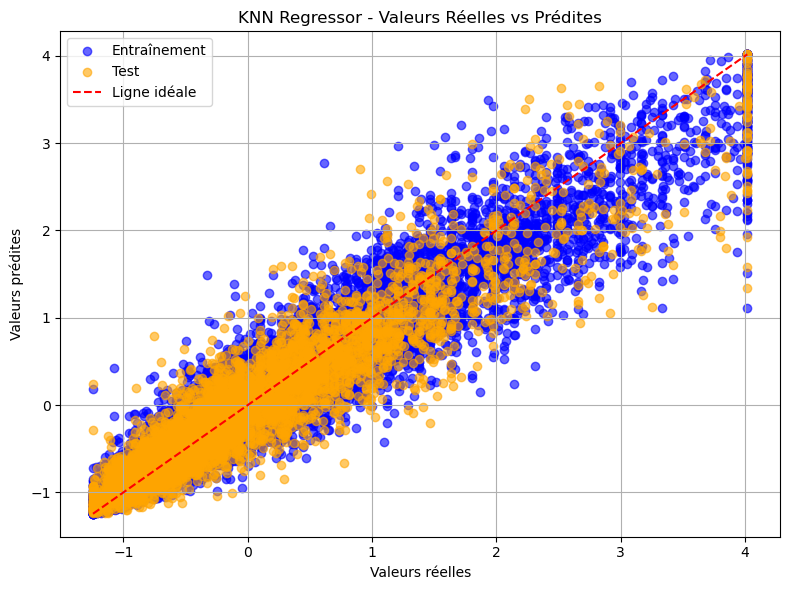

In [89]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Initialiser le modèle KNN
knn = KNeighborsRegressor(n_neighbors=5)  # Tu peux ajuster ce paramètre

# Entraîner le modèle
knn.fit(X_train, y_train)

# Faire des prédictions
y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)

# Calcul des métriques - Train
mae_train = mean_absolute_error(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
r2_train = r2_score(y_train, y_train_pred)

# Calcul des métriques - Test
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)

# Affichage des métriques
print(f"Train MAE: {mae_train}")
print(f"Train MSE: {mse_train}")
print(f"Train R2: {r2_train}")
print(f"Test MAE: {mae_test}")
print(f"Test MSE: {mse_test}")
print(f"Test R2: {r2_test}")

# Graphique des prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color="blue", label="Entraînement", alpha=0.6)
plt.scatter(y_test, y_test_pred, color="orange", label="Test", alpha=0.6)
x_vals = np.linspace(min(min(y_train), min(y_test)), max(max(y_train), max(y_test)), 100)
plt.plot(x_vals, x_vals, 'r--', label="Ligne idéale")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("KNN Regressor - Valeurs Réelles vs Prédites")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Random Forest - Train MAE: 0.0457, Train MSE: 0.0050, Train R2: 0.9950
Random Forest - Test MAE: 0.0488, Test MSE: 0.0069, Test R2: 0.9930


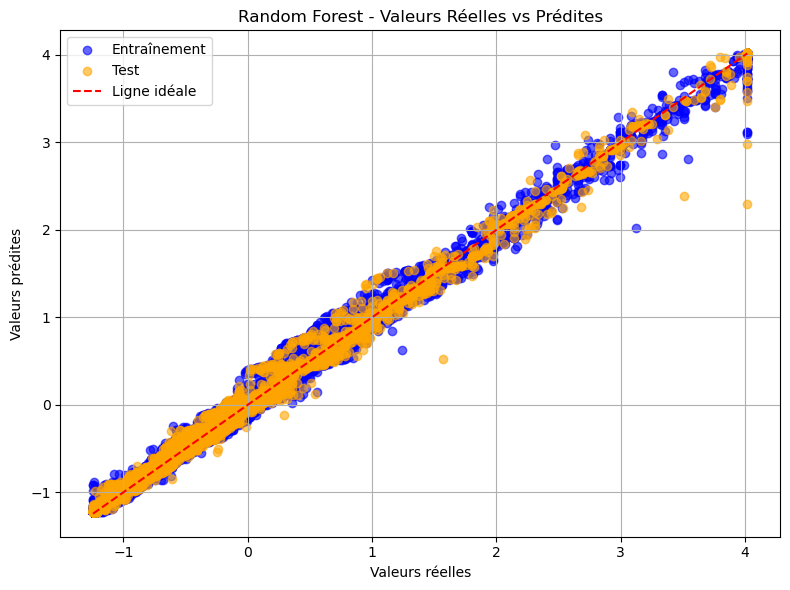

In [90]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Initialiser le modèle RandomForest avec hyperparamètres ajustés
rf = RandomForestRegressor(
    n_estimators=200,       # nombre d'arbres
    max_depth=7,            # profondeur max des arbres
    min_samples_split=5,    # minimum d'échantillons pour splitter un noeud
    min_samples_leaf=5,     # minimum d'échantillons dans une feuille
    random_state=42,
    n_jobs=-1               # utilise tous les coeurs CPU disponibles
)

# Entraîner le modèle
rf.fit(X_train, y_train)

# Prédictions
y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test)

# Calcul des métriques - Train
mae_train = mean_absolute_error(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
r2_train = r2_score(y_train, y_train_pred)

# Calcul des métriques - Test
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)

# Affichage des métriques
print(f"Random Forest - Train MAE: {mae_train:.4f}, Train MSE: {mse_train:.4f}, Train R2: {r2_train:.4f}")
print(f"Random Forest - Test MAE: {mae_test:.4f}, Test MSE: {mse_test:.4f}, Test R2: {r2_test:.4f}")

# Graphique des prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color="blue", label="Entraînement", alpha=0.6)
plt.scatter(y_test, y_test_pred, color="orange", label="Test", alpha=0.6)
x_vals = np.linspace(min(min(y_train), min(y_test)), max(max(y_train), max(y_test)), 100)
plt.plot(x_vals, x_vals, 'r--', label="Ligne idéale")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Random Forest - Valeurs Réelles vs Prédites")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


SVR - Train MAE: 0.0456, Train MSE: 0.0030, Train R2: 0.9970
SVR - Test MAE: 0.0562, Test MSE: 0.0102, Test R2: 0.9896


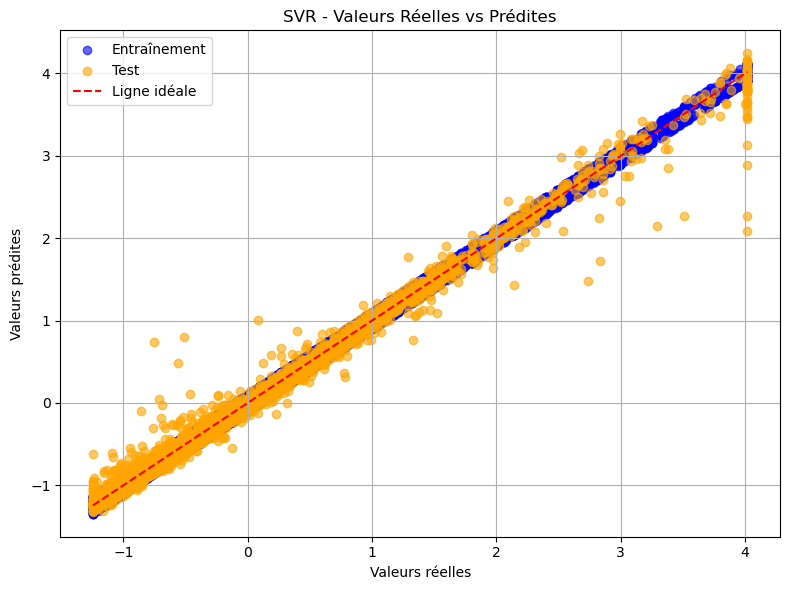

In [94]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Initialiser le modèle SVR avec des hyperparamètres ajustés
svr = SVR(kernel='rbf', C=100, epsilon=0.1, gamma='scale')

# Entraîner le modèle
svr.fit(X_train, y_train)

# Prédictions
y_train_pred = svr.predict(X_train)
y_test_pred = svr.predict(X_test)

# Calcul des métriques - Train
mae_train = mean_absolute_error(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
r2_train = r2_score(y_train, y_train_pred)

# Calcul des métriques - Test
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)

# Affichage des métriques
print(f"SVR - Train MAE: {mae_train:.4f}, Train MSE: {mse_train:.4f}, Train R2: {r2_train:.4f}")
print(f"SVR - Test MAE: {mae_test:.4f}, Test MSE: {mse_test:.4f}, Test R2: {r2_test:.4f}")

# Graphique des prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color="blue", label="Entraînement", alpha=0.6)
plt.scatter(y_test, y_test_pred, color="orange", label="Test", alpha=0.6)
x_vals = np.linspace(min(min(y_train), min(y_test)), max(max(y_train), max(y_test)), 100)
plt.plot(x_vals, x_vals, 'r--', label="Ligne idéale")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("SVR - Valeurs Réelles vs Prédites")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

CatBoost - Train MAE: 0.0180, Train MSE: 0.0009, Train R2: 0.9991
CatBoost - Test MAE: 0.0207, Test MSE: 0.0049, Test R2: 0.9951


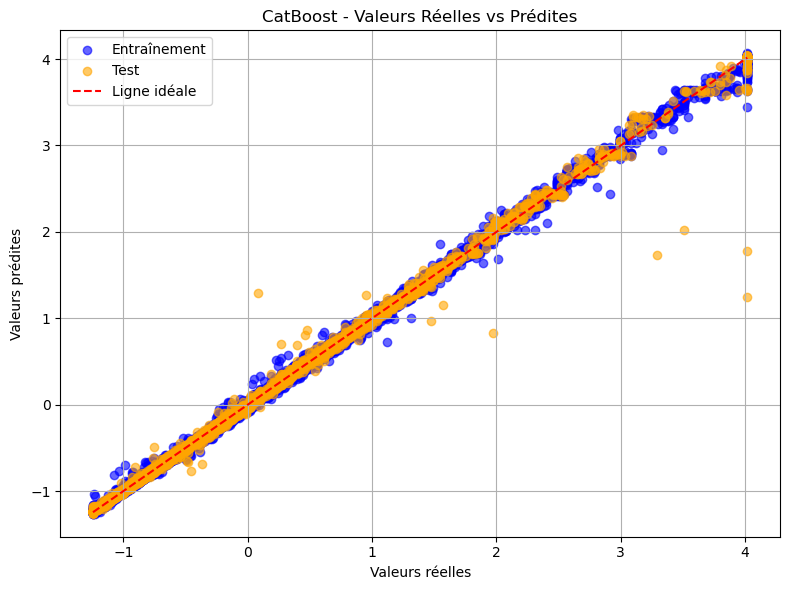

In [95]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Initialiser le modèle CatBoost
model_cat = CatBoostRegressor(
    iterations=300,
    depth=7,
    learning_rate=0.05,
    loss_function='RMSE',
    random_seed=42,
    verbose=0  # pour ne pas afficher l'entraînement
)

# Entraîner le modèle
model_cat.fit(X_train, y_train)

# Prédictions
y_train_pred = model_cat.predict(X_train)
y_test_pred = model_cat.predict(X_test)

# Calcul des métriques - Train
mae_train = mean_absolute_error(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
r2_train = r2_score(y_train, y_train_pred)

# Calcul des métriques - Test
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)

# Affichage des métriques
print(f"CatBoost - Train MAE: {mae_train:.4f}, Train MSE: {mse_train:.4f}, Train R2: {r2_train:.4f}")
print(f"CatBoost - Test MAE: {mae_test:.4f}, Test MSE: {mse_test:.4f}, Test R2: {r2_test:.4f}")

# Graphique des prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color="blue", label="Entraînement", alpha=0.6)
plt.scatter(y_test, y_test_pred, color="orange", label="Test", alpha=0.6)
x_vals = np.linspace(min(min(y_train), min(y_test)), max(max(y_train), max(y_test)), 100)
plt.plot(x_vals, x_vals, 'r--', label="Ligne idéale")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("CatBoost - Valeurs Réelles vs Prédites")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006247 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3387
[LightGBM] [Info] Number of data points in the train set: 21797, number of used features: 26
[LightGBM] [Info] Start training from score 0.000185
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

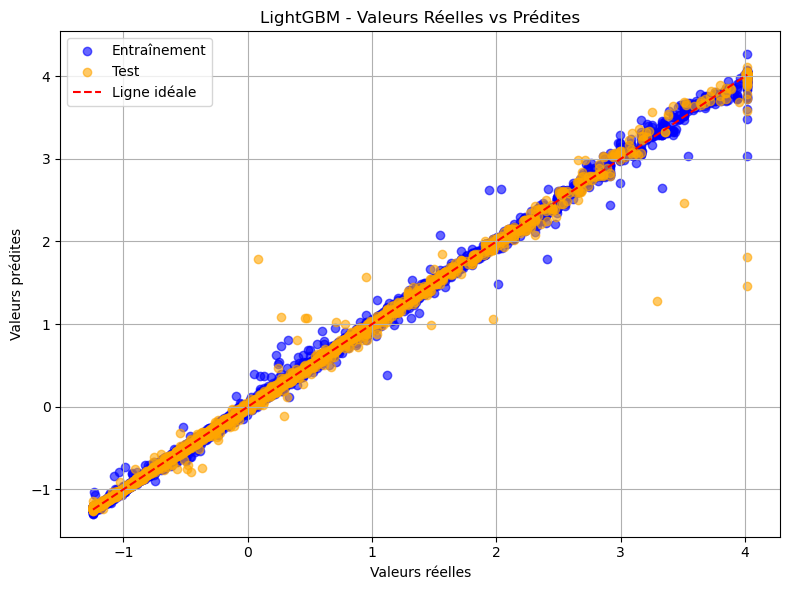

In [98]:
import lightgbm as lgb
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initialiser le modèle LightGBM Regressor avec paramètres personnalisés
model_lgb = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=7,
    num_leaves=31,
    random_state=42
)

# Entraîner le modèle
model_lgb.fit(X_train, y_train)

# Prédictions sur train et test
y_train_pred = model_lgb.predict(X_train)
y_test_pred = model_lgb.predict(X_test)

# Calcul des métriques sur train
train_mae = mean_absolute_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Calcul des métriques sur test
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Affichage des métriques
print(f"LightGBM - Train MAE: {train_mae:.4f}, Train MSE: {train_mse:.4f}, Train R2: {train_r2:.4f}")
print(f"LightGBM - Test MAE: {test_mae:.4f}, Test MSE: {test_mse:.4f}, Test R2: {test_r2:.4f}")

# Graphique des prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color="blue", label="Entraînement", alpha=0.6)
plt.scatter(y_test, y_test_pred, color="orange", label="Test", alpha=0.6)
x_vals = np.linspace(min(min(y_train), min(y_test)), max(max(y_train), max(y_test)), 100)
plt.plot(x_vals, x_vals, 'r--', label="Ligne idéale")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("LightGBM - Valeurs Réelles vs Prédites")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Decision Tree - Train MAE: 0.0817, Train MSE: 0.0134, Train R2: 0.9867
Decision Tree - Test MAE: 0.0856, Test MSE: 0.0165, Test R2: 0.9832


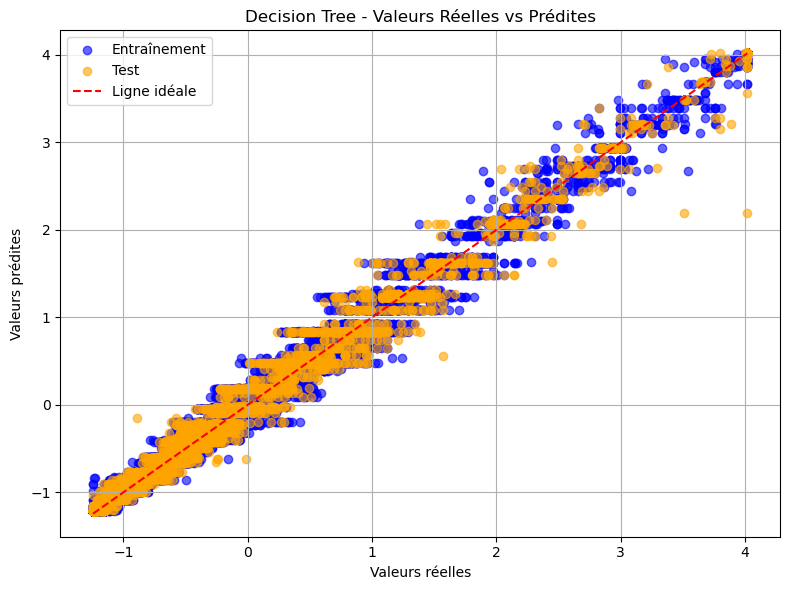

In [100]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Initialiser le modèle Decision Tree Regressor
model_dt = DecisionTreeRegressor(
    max_depth=7,
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42
)

# Entraîner le modèle
model_dt.fit(X_train, y_train)

# Prédictions sur train et test
y_train_pred = model_dt.predict(X_train)
y_test_pred = model_dt.predict(X_test)

# Calcul des métriques sur train
train_mae = mean_absolute_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Calcul des métriques sur test
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Affichage des métriques
print(f"Decision Tree - Train MAE: {train_mae:.4f}, Train MSE: {train_mse:.4f}, Train R2: {train_r2:.4f}")
print(f"Decision Tree - Test MAE: {test_mae:.4f}, Test MSE: {test_mse:.4f}, Test R2: {test_r2:.4f}")

# Graphique des prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color="blue", label="Entraînement", alpha=0.6)
plt.scatter(y_test, y_test_pred, color="orange", label="Test", alpha=0.6)
x_vals = np.linspace(min(min(y_train), min(y_test)), max(max(y_train), max(y_test)), 100)
plt.plot(x_vals, x_vals, 'r--', label="Ligne idéale")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("Decision Tree - Valeurs Réelles vs Prédites")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


AdaBoost - Train MAE: 0.1470, Train MSE: 0.0399, Train R2: 0.9603
AdaBoost - Test MAE: 0.1462, Test MSE: 0.0407, Test R2: 0.9587


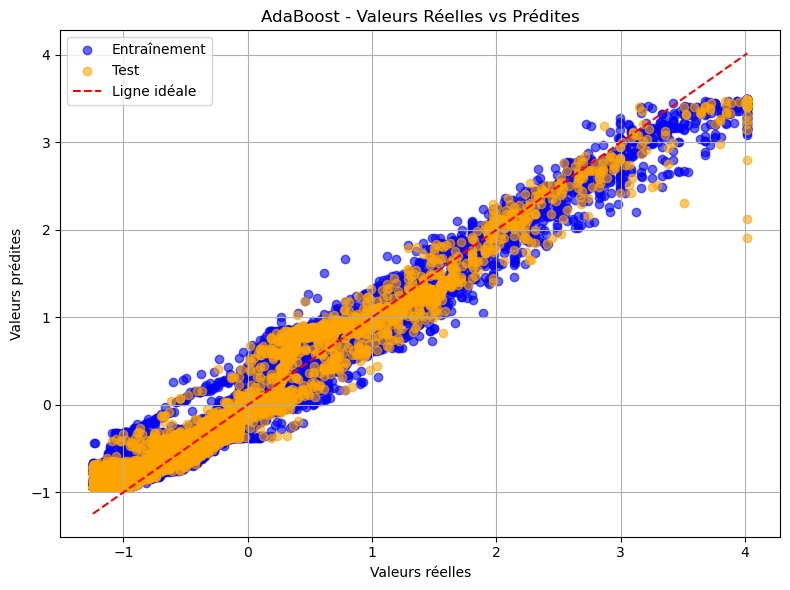

In [102]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt

# Base estimator avec profondeur limitée pour éviter l'overfitting
base_dt = DecisionTreeRegressor(max_depth=4, random_state=42)

# AdaBoost avec plus d’arbres, learning rate plus faible pour un entraînement plus fin
ada = AdaBoostRegressor(
    estimator=base_dt,        # <-- ici, remplacer base_estimator par estimator
    n_estimators=500,
    learning_rate=0.03,
    random_state=42
)

# Entraîner le modèle
ada.fit(X_train, y_train)

# Prédictions
y_train_pred = ada.predict(X_train)
y_test_pred = ada.predict(X_test)

# Calcul métriques train
train_mae = mean_absolute_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

# Calcul métriques test
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Affichage
print(f"AdaBoost - Train MAE: {train_mae:.4f}, Train MSE: {train_mse:.4f}, Train R2: {train_r2:.4f}")
print(f"AdaBoost - Test MAE: {test_mae:.4f}, Test MSE: {test_mse:.4f}, Test R2: {test_r2:.4f}")

# Graphique des prédictions
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color="blue", label="Entraînement", alpha=0.6)
plt.scatter(y_test, y_test_pred, color="orange", label="Test", alpha=0.6)
x_vals = np.linspace(min(min(y_train), min(y_test)), max(max(y_train), max(y_test)), 100)
plt.plot(x_vals, x_vals, 'r--', label="Ligne idéale")
plt.xlabel("Valeurs réelles")
plt.ylabel("Valeurs prédites")
plt.title("AdaBoost - Valeurs Réelles vs Prédites")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

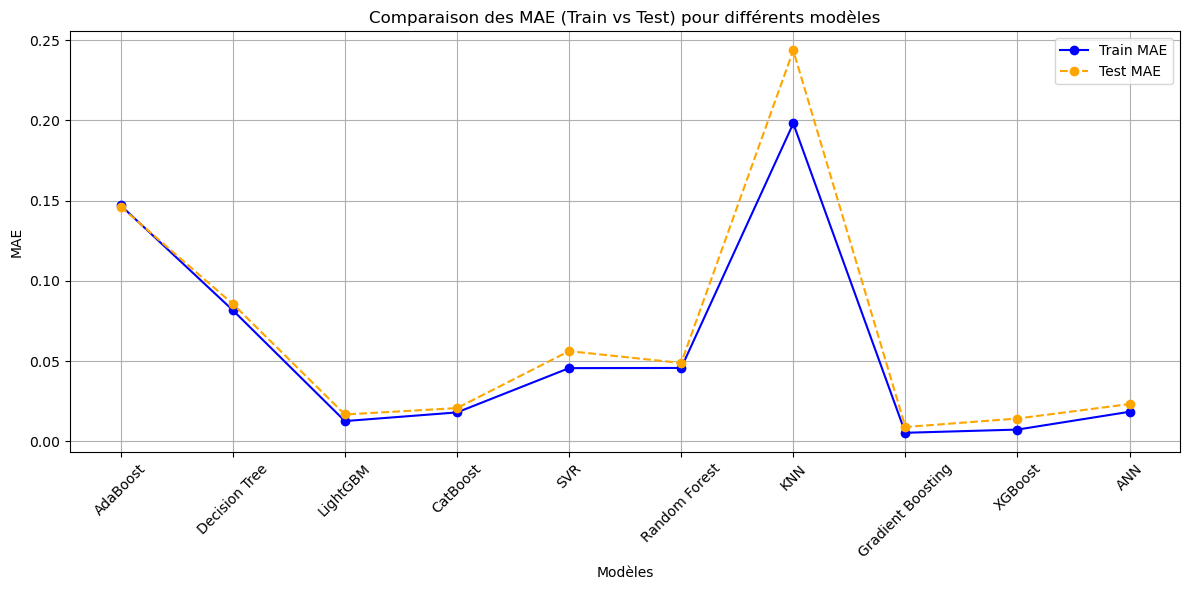

In [104]:
import matplotlib.pyplot as plt

# Liste des modèles
models = ['AdaBoost', 'Decision Tree', 'LightGBM', 'CatBoost', 'SVR',
          'Random Forest', 'KNN', 'Gradient Boosting', 'XGBoost', 'ANN']

# MAE pour l'ensemble d'entraînement
train_mae = [0.1470, 0.0817, 0.0126, 0.0180, 0.0456, 0.0457, 0.1981, 0.0053, 0.0073, 0.0184]

# MAE pour l'ensemble de test
test_mae = [0.1462, 0.0856, 0.0167, 0.0207, 0.0562, 0.0488, 0.2436, 0.0089, 0.0142, 0.0232]

# Création du graphique
plt.figure(figsize=(12, 6))
plt.plot(models, train_mae, marker='o', linestyle='-', label='Train MAE', color='blue')
plt.plot(models, test_mae, marker='o', linestyle='--', label='Test MAE', color='orange')

# Personnalisation
plt.title('Comparaison des MAE (Train vs Test) pour différents modèles')
plt.xlabel('Modèles')
plt.ylabel('MAE')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
